# CNN-MSGPP Decoder: RGB to NIR/Red-Edge Reconstruction

Spectral reconstruction from RGB to NIR/Red-Edge (Sentinel-2) using a CNN stem with MSG++ style spectral mixing blocks.

## Architecture
1. **CNN Stem** - Local feature extraction with convolutional layers
2. **MSG++ Blocks** - Spatial mixing (DWConv) + Spectral Attention + MLP
3. **Convolutional Decoder** - Final reconstruction to 4 bands (B5, B6, B7, B8)

## Key Features
- Spectral attention operates on C x C (channels) instead of N x N (spatial)
- Memory-efficient: 65K values vs 268M for spatial attention
- Mixed Precision (fp16) support for faster training
- Synchronized data augmentation with validity mask

## 1. Configuration and Imports

In [ ]:
import tensorflow as tf
import numpy as np
import math
from tensorflow import keras
from tensorflow.keras import layers

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
import os
import shutil

drive.mount('/content/drive')

DRIVE_SAVE_PATH = '/content/drive/MyDrive/CNN_MSGPP_Checkpoints'
os.makedirs(DRIVE_SAVE_PATH, exist_ok=True)

print(f"Google Drive mounted")
print(f"Checkpoint folder: {DRIVE_SAVE_PATH}")

def sync_to_drive(local_path, drive_path=DRIVE_SAVE_PATH):
    """Copy file or folder to Google Drive."""
    if os.path.isfile(local_path):
        dst = os.path.join(drive_path, os.path.basename(local_path))
        shutil.copy2(local_path, dst)
        print(f"  Copied to Drive: {os.path.basename(local_path)}")
    elif os.path.isdir(local_path):
        dst = os.path.join(drive_path, os.path.basename(local_path))
        if os.path.exists(dst):
            shutil.rmtree(dst)
        shutil.copytree(local_path, dst)
        print(f"  Folder copied to Drive: {os.path.basename(local_path)}")

def restore_from_drive(drive_path=DRIVE_SAVE_PATH, local_path='.'):
    """Restore checkpoints from Drive."""
    if os.path.exists(drive_path):
        for item in os.listdir(drive_path):
            src = os.path.join(drive_path, item)
            dst = os.path.join(local_path, item)
            if os.path.isfile(src):
                shutil.copy2(src, dst)
                print(f"  Restored: {item}")
            elif os.path.isdir(src):
                if os.path.exists(dst):
                    shutil.rmtree(dst)
                shutil.copytree(src, dst)
                print(f"  Folder restored: {item}")
        print("Restoration complete!")
    else:
        print("No backup found on Drive")

print("\nTo restore after disconnection, run:")
print("   restore_from_drive()")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Google Drive monté
✓ Dossier de sauvegarde: /content/drive/MyDrive/CNN_MSGPP_Checkpoints

📌 Pour restaurer après déconnexion, exécutez:
   restore_from_drive()


### Deep Learning Utilities

| Technique | Purpose |
|-----------|---------|
| **Swish/SiLU** | Smoother activation than ReLU, better convergence |
| **DropPath** | Regularization for Transformers, random block drop |
| **EMA** | Exponential Moving Average of weights for stable models |
| **Gradient Clipping** | Prevents gradient explosion |
| **LR Warmup** | Progressive LR increase at start |
| **RMSNorm** | Faster than LayerNorm, often better |
| **QK Normalization** | Stabilizes attention for large dimensions |

In [ ]:
import math

def get_activation(name):
    """Returns activation name for Keras 3."""
    activations = {
        'relu': 'relu',
        'gelu': 'gelu',
        'swish': 'swish',
        'silu': 'swish',
        'mish': 'mish',
    }
    if name.lower() not in activations:
        raise ValueError(f"Unknown activation: {name}. Options: {list(activations.keys())}")
    return activations[name.lower()]


def get_activation_layer(name):
    """Returns a Keras Activation layer."""
    activation_name = get_activation(name)
    return layers.Activation(activation_name)


def get_initializer(activation='relu'):
    """Returns appropriate initializer based on activation."""
    if activation in ['relu', 'leaky_relu', 'elu']:
        return tf.keras.initializers.HeNormal()
    else:
        return tf.keras.initializers.GlorotUniform()


class DropPath(layers.Layer):
    """Stochastic Depth / DropPath (Huang et al., 2016)"""
    def __init__(self, drop_prob=0.1, **kwargs):
        super().__init__(**kwargs)
        self.drop_prob = drop_prob

    def call(self, x, training=None):
        if not training or self.drop_prob == 0:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (tf.shape(x)[0],) + (1,) * (len(x.shape) - 1)
        random_tensor = keep_prob + tf.random.uniform(shape, dtype=x.dtype)
        binary_mask = tf.floor(random_tensor)
        return x / keep_prob * binary_mask

    def get_config(self):
        config = super().get_config()
        config.update({'drop_prob': self.drop_prob})
        return config


class RMSNorm(layers.Layer):
    """Root Mean Square Layer Normalization (Zhang & Sennrich, 2019)"""
    def __init__(self, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.gamma = self.add_weight(
            name='gamma',
            shape=(input_shape[-1],),
            initializer='ones',
            trainable=True
        )

    def call(self, x):
        x_float = tf.cast(x, tf.float32)
        rms = tf.sqrt(tf.reduce_mean(tf.square(x_float), axis=-1, keepdims=True) + self.eps)
        x_normed = x_float / rms
        gamma = tf.cast(self.gamma, x_float.dtype)
        result = x_normed * gamma
        return tf.cast(result, x.dtype)

    def get_config(self):
        config = super().get_config()
        config.update({'eps': self.eps})
        return config


class EMA:
    """Exponential Moving Average of model weights."""
    def __init__(self, model, decay=0.9999):
        self.model = model
        self.decay = decay
        self.ema_weights = [tf.Variable(w, trainable=False) for w in model.weights]

    def update(self):
        for ema_w, model_w in zip(self.ema_weights, self.model.weights):
            ema_w.assign(self.decay * ema_w + (1 - self.decay) * model_w)

    def apply_to_model(self):
        self.backup_weights = [tf.Variable(w) for w in self.model.weights]
        for model_w, ema_w in zip(self.model.weights, self.ema_weights):
            model_w.assign(ema_w)

    def restore_model(self):
        for model_w, backup_w in zip(self.model.weights, self.backup_weights):
            model_w.assign(backup_w)


class WarmupCosineDecay(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Learning Rate Schedule with Warmup + Cosine Decay."""
    def __init__(self, initial_lr, warmup_steps, total_steps, min_lr=1e-6):
        super().__init__()
        self.initial_lr = initial_lr
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.min_lr = min_lr

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warmup_steps = tf.cast(self.warmup_steps, tf.float32)
        total_steps = tf.cast(self.total_steps, tf.float32)

        warmup_progress = step / tf.maximum(warmup_steps, 1.0)
        warmup_lr = self.min_lr + (self.initial_lr - self.min_lr) * warmup_progress

        decay_steps = total_steps - warmup_steps
        cosine_progress = (step - warmup_steps) / tf.maximum(decay_steps, 1.0)
        cosine_decay = 0.5 * (1 + tf.cos(math.pi * cosine_progress))
        decay_lr = self.min_lr + (self.initial_lr - self.min_lr) * cosine_decay

        return tf.where(step < warmup_steps, warmup_lr, decay_lr)

    def get_config(self):
        return {
            'initial_lr': self.initial_lr,
            'warmup_steps': self.warmup_steps,
            'total_steps': self.total_steps,
            'min_lr': self.min_lr
        }

print("Advanced utilities defined")

✓ Outils avancés définis:
  - get_activation() : relu, gelu, swish, mish
  - get_activation_layer() : retourne layers.Activation
  - get_initializer() : He/Glorot selon activation
  - DropPath : Stochastic Depth
  - RMSNorm : Normalisation plus efficace
  - EMA : Exponential Moving Average
  - WarmupCosineDecay : LR schedule optimal (commence à min_lr, pas 0)


In [ ]:
class Config:
    """CNN_MSGPP Decoder configuration."""

    # GCS Data
    BUCKET = 'gee_nir_to_rgb'
    FOLDER = 'dataset_training_mst'
    PATCH_SIZE = 128
    INPUT_CHANNELS = 3
    OUTPUT_CHANNELS = 4

    # Output constraint
    OUTPUT_CONSTRAINT = "tanh"
    OUTPUT_MIN = 0.0
    OUTPUT_MAX = 1.0

    # Architecture
    BASE_DIM = 112
    NUM_HEADS = 8
    NUM_MSGPP_BLOCKS = 4
    MLP_RATIO = 4
    DROPOUT = 0.1
    DROP_PATH_RATE = 0.15

    SPATIAL_KERNEL = 7
    SPATIAL_EXPANSION = 2
    STEM_RMSNORM = True

    # Training
    BATCH_SIZE = 32
    EPOCHS = 25
    LEARNING_RATE = 8e-4

    WARMUP_STEPS = 300
    WARMUP_MIN_LR = 1e-5

    # Loss weights (L1 + SAM only)
    LAMBDA_L1 = 1.0
    LAMBDA_SAM = 0.5
    SAM_MODE = "cosine"
    SAM_LOSS_SCALE = 1.0
    LAMBDA_FREQ = 0.0
    LAMBDA_WAVELET = 0.0

    # Per-band L1 weights (B5, B6, B7, B8)
    USE_BAND_L1_WEIGHTS = True
    BAND_L1_WEIGHTS = [1.5, 1.0, 1.0, 2.0]

    # Stability
    USE_MIXED_PRECISION = True
    GRADIENT_CLIP_NORM = 1.0
    USE_EMA = True
    EMA_DECAY = 0.999

    # Activation
    ACTIVATION = 'gelu'

    # Drive checkpointing
    SAVE_TO_DRIVE = True
    DRIVE_PATH = '/content/drive/MyDrive/CNN_MSGPP_Checkpoints'

config = Config()

print("Configuration CNN_MSGPP Decoder v1")
print(f"  Architecture:")
print(f"    - BASE_DIM: {config.BASE_DIM}")
print(f"    - NUM_HEADS: {config.NUM_HEADS}")
print(f"    - NUM_MSGPP_BLOCKS: {config.NUM_MSGPP_BLOCKS}")
print(f"    - MLP_RATIO: {config.MLP_RATIO}")
print(f"  Loss: L1 + SAM")
print(f"  Training:")
print(f"    - BATCH_SIZE: {config.BATCH_SIZE}")
print(f"    - LEARNING_RATE: {config.LEARNING_RATE}")
print(f"    - MIXED PRECISION: {config.USE_MIXED_PRECISION}")

✓ Configuration CNN_MSGPP Decoder v1 (Optimisée)
  Architecture:
    - BASE_DIM: 112
    - NUM_HEADS: 8
    - NUM_MSGPP_BLOCKS: 4
    - MLP_RATIO: 4
  Loss: L1 + SAM (freq/wavelet desactives)
  Training:
    - BATCH_SIZE: 32 (Safe start)
    - LEARNING_RATE: 0.0008
    - MIXED PRECISION: True
  Drive: /content/drive/MyDrive/CNN_MSGPP_Checkpoints


## 2. Haar Wavelet Transform (DWT) Layers

2D Haar Wavelet Transform - mathematically exact decomposition.

Decomposes image into 4 sub-bands:
- **LL (Approximation)**: Low frequencies (average)
- **LH (Horizontal)**: Horizontal details
- **HL (Vertical)**: Vertical details
- **HH (Diagonal)**: Diagonal details

Filters are **fixed** (non-trainable) to guarantee mathematically exact decomposition.

In [ ]:
class HaarWavelet2D(layers.Layer):
    """2D Haar Wavelet Transform - mathematically exact.
    
    Computes in float32 for numerical stability with Mixed Precision.
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        sqrt2 = np.sqrt(2)
        L = np.array([1, 1]) / sqrt2
        H = np.array([1, -1]) / sqrt2

        self.filter_LL = self.add_weight(
            name='filter_LL', shape=(2, 2, 1, 1),
            initializer=tf.constant_initializer(np.outer(L, L).reshape(2, 2, 1, 1)),
            trainable=False, dtype='float32'
        )
        self.filter_LH = self.add_weight(
            name='filter_LH', shape=(2, 2, 1, 1),
            initializer=tf.constant_initializer(np.outer(L, H).reshape(2, 2, 1, 1)),
            trainable=False, dtype='float32'
        )
        self.filter_HL = self.add_weight(
            name='filter_HL', shape=(2, 2, 1, 1),
            initializer=tf.constant_initializer(np.outer(H, L).reshape(2, 2, 1, 1)),
            trainable=False, dtype='float32'
        )
        self.filter_HH = self.add_weight(
            name='filter_HH', shape=(2, 2, 1, 1),
            initializer=tf.constant_initializer(np.outer(H, H).reshape(2, 2, 1, 1)),
            trainable=False, dtype='float32'
        )

        super().build(input_shape)

    def call(self, x):
        """
        Input:  (B, H, W, C)
        Output: dict with LL, LH, HL, HH of shape (B, H/2, W/2, C)
        """
        x_f32 = tf.cast(x, tf.float32)
        C = tf.shape(x_f32)[-1]

        results = {}
        filters = {
            'LL': self.filter_LL,
            'LH': self.filter_LH,
            'HL': self.filter_HL,
            'HH': self.filter_HH
        }

        for name, filt in filters.items():
            filt_f32 = tf.cast(filt, tf.float32)
            filt_expanded = tf.tile(filt_f32, [1, 1, C, 1])
            out = tf.nn.depthwise_conv2d(
                x_f32, filt_expanded,
                strides=[1, 2, 2, 1],
                padding='SAME'
            )
            results[name] = tf.cast(out, x.dtype)

        return results


class MultiLevelDWT(layers.Layer):
    """Multi-level DWT: pyramidal decomposition."""
    def __init__(self, num_levels=2, **kwargs):
        super().__init__(**kwargs)
        self.num_levels = num_levels

    def build(self, input_shape):
        self.dwt_layers = [HaarWavelet2D(name=f'dwt_level_{i}')
                          for i in range(self.num_levels)]
        super().build(input_shape)

    def call(self, x):
        all_details = []
        current = x

        for level, dwt in enumerate(self.dwt_layers):
            coeffs = dwt(current)
            all_details.append({
                'level': level,
                'LH': coeffs['LH'],
                'HL': coeffs['HL'],
                'HH': coeffs['HH'],
                'LL': coeffs['LL']
            })
            current = coeffs['LL']

        return all_details, current

print("HaarWavelet2D and MultiLevelDWT defined")

✓ HaarWavelet2D et MultiLevelDWT définis (calculs en float32 pour stabilité)


## 3. DWT Feature Extractor

Combines multi-level DWT coefficients with learnable projections.

**Upsampling strategy:**
- **Details (LH, HL, HH)**: NEAREST neighbor - preserves high frequencies
- **Approximation (LL)**: BILINEAR - OK for low frequencies

Bilinear interpolation is a low-pass filter that would destroy high frequencies!

In [ ]:
class DWTFeatureExtractor(layers.Layer):
    """Feature extractor based on multi-level DWT."""
    def __init__(self, num_levels=2, output_dim=64, activation='swish', **kwargs):
        super().__init__(**kwargs)
        self.num_levels = num_levels
        self.output_dim = output_dim
        self.activation_name = get_activation(activation)
        self.initializer = get_initializer(activation)

    def build(self, input_shape):
        self.dwt = MultiLevelDWT(self.num_levels)

        detail_dim = max(self.output_dim // (self.num_levels + 1), 16)
        approx_dim = self.output_dim - (detail_dim * self.num_levels)

        self.detail_projs = []
        self.detail_activations = []
        self.detail_upsamplers = []

        for level in range(self.num_levels):
            self.detail_projs.append(
                layers.Conv2D(detail_dim, 1, kernel_initializer=self.initializer,
                              name=f'detail_proj_level_{level}')
            )
            self.detail_activations.append(
                layers.Activation(self.activation_name, name=f'detail_act_level_{level}')
            )
            scale_factor = 2 ** (level + 1)
            self.detail_upsamplers.append(
                layers.UpSampling2D(size=scale_factor, interpolation='nearest')
            )

        self.approx_proj = layers.Conv2D(max(approx_dim, 16), 1,
                                         kernel_initializer=self.initializer,
                                         name='approx_proj')
        self.approx_activation = layers.Activation(self.activation_name, name='approx_act')
        self.approx_upsampler = layers.UpSampling2D(size=2**self.num_levels,
                                                    interpolation='bilinear')

        self.fusion = layers.Conv2D(self.output_dim, 1,
                                    kernel_initializer=self.initializer,
                                    name='dwt_fusion')
        super().build(input_shape)

    def call(self, x):
        input_shape = tf.shape(x)
        H, W = input_shape[1], input_shape[2]

        details_by_level, final_approx = self.dwt(x)

        features = []

        for level, (detail_proj, detail_act, upsampler) in enumerate(
            zip(self.detail_projs, self.detail_activations, self.detail_upsamplers)
        ):
            level_details = details_by_level[level]
            detail_concat = tf.concat([
                level_details['LH'],
                level_details['HL'],
                level_details['HH']
            ], axis=-1)

            projected = detail_proj(detail_concat)
            projected = detail_act(projected)
            upsampled = upsampler(projected)
            features.append(upsampled)

        approx_proj = self.approx_proj(final_approx)
        approx_proj = self.approx_activation(approx_proj)
        approx_upsampled = self.approx_upsampler(approx_proj)
        features.append(approx_upsampled)

        features_aligned = [tf.image.resize(f, [H, W], method='nearest') for f in features]

        all_features = tf.concat(features_aligned, axis=-1)
        output = self.fusion(all_features)

        return output

print("DWTFeatureExtractor defined")

✓ DWTFeatureExtractor (dimensions sécurisées)


## 4. True Spectral Attention (MST++ Style)

**Key difference vs standard spatial attention:**

| Type | Matrix | Size (128x128 image) | Memory |
|------|--------|----------------------|--------|
| Spatial | N x N where N=H*W | 16384 x 16384 | **268M values** |
| **Spectral** | C x C where C=256 | 256 x 256 | **65K values** |

Spectral attention asks: *"How does channel i influence channel j?"*
This is exactly what we need for spectral reconstruction RGB to NIR.

In [ ]:
class TrueSpectralAttention(layers.Layer):
    """True Spectral Attention optimized for memory.
    
    Critical computations in float32 for stability.
    """
    def __init__(self, dim, num_heads, qk_norm=True, **kwargs):
        super().__init__(**kwargs)
        if dim % num_heads != 0:
            raise ValueError(f"dim ({dim}) must be divisible by num_heads ({num_heads})")
        self.num_heads = num_heads
        self.dim = dim
        self.head_dim = dim // num_heads
        self.qk_norm = qk_norm

    def build(self, input_shape):
        init = tf.keras.initializers.TruncatedNormal(stddev=0.02)
        self.qkv = layers.Dense(self.dim * 3, use_bias=False,
                                kernel_initializer=init, name='qkv_proj')
        self.proj = layers.Dense(self.dim, kernel_initializer=init, name='out_proj')

        if self.qk_norm:
            self.q_norm = RMSNorm(name='q_norm')
            self.k_norm = RMSNorm(name='k_norm')
        super().build(input_shape)

    def call(self, x, training=False):
        input_dtype = x.dtype
        B = tf.shape(x)[0]
        H = tf.shape(x)[1]
        W = tf.shape(x)[2]
        C = self.dim
        N = tf.cast(H, tf.int64) * tf.cast(W, tf.int64)
        N_i32 = tf.cast(N, tf.int32)

        x_flat = tf.reshape(x, (B, N_i32, C))

        qkv = self.qkv(x_flat)
        qkv = tf.reshape(qkv, (B, N_i32, 3, C))
        q, k, v = qkv[:, :, 0], qkv[:, :, 1], qkv[:, :, 2]

        if self.qk_norm:
            q = self.q_norm(q)
            k = self.k_norm(k)

        q = tf.reshape(q, (B, N_i32, self.num_heads, self.head_dim))
        k = tf.reshape(k, (B, N_i32, self.num_heads, self.head_dim))
        v = tf.reshape(v, (B, N_i32, self.num_heads, self.head_dim))
        q = tf.transpose(q, (0, 2, 1, 3))
        k = tf.transpose(k, (0, 2, 1, 3))
        v = tf.transpose(v, (0, 2, 1, 3))

        # Spectral attention in float32 for stability
        q_f32 = tf.cast(q, tf.float32)
        k_f32 = tf.cast(k, tf.float32)
        v_f32 = tf.cast(v, tf.float32)

        q_t = tf.transpose(q_f32, (0, 1, 3, 2))
        scale_n = tf.math.rsqrt(tf.cast(N, tf.float32))
        attn = tf.matmul(q_t, k_f32) * scale_n

        attn = attn - tf.reduce_max(attn, axis=-1, keepdims=True)
        attn = tf.nn.softmax(attn, axis=-1)

        v_t = tf.transpose(v_f32, (0, 1, 3, 2))
        out = tf.matmul(attn, v_t)

        out = tf.transpose(out, (0, 1, 3, 2))
        out = tf.reshape(out, (B, N_i32, C))

        out = tf.cast(out, input_dtype)
        out = self.proj(out)
        out = tf.reshape(out, (B, H, W, C))

        return out


class ChannelAttention(layers.Layer):
    """Channel attention (SE-style) with Swish."""
    def __init__(self, channels, reduction=8, activation='swish', **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.reduction = reduction
        self.activation_name = get_activation(activation)

    def build(self, input_shape):
        init = get_initializer('swish')
        reduced_channels = max(self.channels // self.reduction, 4)
        self.fc1 = layers.Dense(reduced_channels, kernel_initializer=init)
        self.activation = layers.Activation(self.activation_name)
        self.fc2 = layers.Dense(self.channels,
                                kernel_initializer=tf.keras.initializers.GlorotNormal())
        super().build(input_shape)

    def call(self, x):
        gap = tf.reduce_mean(x, axis=[1, 2], keepdims=True)
        squeeze = tf.squeeze(gap, axis=[1, 2])

        excite = self.fc1(squeeze)
        excite = self.activation(excite)
        excite = self.fc2(excite)
        excite = tf.nn.sigmoid(excite)
        excite = tf.reshape(excite, (-1, 1, 1, self.channels))

        return x * excite

print("TrueSpectralAttention defined")

✓ TrueSpectralAttention STABLE (calculs critiques en float32)


## 5. Spectral Transformer Block

Complete Transformer block combining:
1. **True Spectral Attention** (C x C) - channel correlations
2. **Channel Attention** (SE-style) - global recalibration
3. **Feed-Forward MLP** with GELU activation
4. **Residual connections** + LayerNorm

In [ ]:
class SpatialMixerDWConv(layers.Layer):
    """Lightweight spatial mixing: depthwise conv + pointwise conv."""
    def __init__(self, channels, kernel_size=7, expansion=2, drop_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.kernel_size = kernel_size
        self.expansion = expansion
        self.drop_rate = drop_rate

    def build(self, input_shape):
        self.norm = RMSNorm(name='norm')
        self.dwconv = layers.DepthwiseConv2D(
            self.kernel_size, padding='same',
            depthwise_initializer='he_normal',
            name='dwconv'
        )
        self.pwconv_expand = layers.Conv2D(
            self.channels * self.expansion, 1,
            padding='same',
            kernel_initializer='he_normal',
            name='pwconv_expand'
        )
        self.act = layers.Activation('gelu', name='gelu')
        self.pwconv_project = layers.Conv2D(
            self.channels, 1,
            padding='same',
            kernel_initializer='he_normal',
            name='pwconv_project'
        )
        self.drop = layers.Dropout(self.drop_rate) if self.drop_rate > 0 else None
        super().build(input_shape)

    def call(self, x, training=False):
        y = self.norm(x)
        y = self.dwconv(y)
        y = self.pwconv_expand(y)
        y = self.act(y)
        y = self.pwconv_project(y)
        if self.drop is not None:
            y = self.drop(y, training=training)
        return y

    def get_config(self):
        config = super().get_config()
        config.update({
            'channels': self.channels,
            'kernel_size': self.kernel_size,
            'expansion': self.expansion,
            'drop_rate': self.drop_rate,
        })
        return config


class SpectralTransformerBlock(layers.Layer):
    """Memory-optimized Transformer block with Pre-Norm, RMSNorm, and DropPath."""
    def __init__(self, embed_dim, num_heads, mlp_ratio=4, dropout=0.1,
                 drop_path=0.0, activation='gelu',
                 use_spatial_mixing=False, spatial_kernel=7, spatial_expansion=2,
                 use_channel_attention=False,
                 **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.mlp_ratio = mlp_ratio
        self.dropout_rate = dropout
        self.drop_path_rate = drop_path
        self.activation_name = activation
        self.use_spatial_mixing = use_spatial_mixing
        self.spatial_kernel = spatial_kernel
        self.spatial_expansion = spatial_expansion
        self.use_channel_attention = use_channel_attention

    def build(self, input_shape):
        self.norm1 = RMSNorm(name='norm1')
        self.norm2 = RMSNorm(name='norm2')

        if self.use_spatial_mixing:
            self.spatial_mix = SpatialMixerDWConv(
                self.embed_dim,
                kernel_size=self.spatial_kernel,
                expansion=self.spatial_expansion,
                drop_rate=self.dropout_rate,
                name='spatial_mix'
            )

        self.spectral_attn = TrueSpectralAttention(self.embed_dim, self.num_heads, qk_norm=True)
        if self.use_channel_attention:
            self.channel_attn = ChannelAttention(self.embed_dim, activation='swish')

        self.drop_path = DropPath(self.drop_path_rate) if self.drop_path_rate > 0 else lambda x, training: x

        init = get_initializer(self.activation_name)
        mlp_hidden = self.embed_dim * self.mlp_ratio

        self.mlp = keras.Sequential([
            layers.Dense(mlp_hidden, kernel_initializer=init),
            layers.Activation(get_activation(self.activation_name)),
            layers.Dropout(self.dropout_rate),
            layers.Dense(self.embed_dim, kernel_initializer=init),
            layers.Dropout(self.dropout_rate)
        ], name='mlp')

        super().build(input_shape)

    def call(self, x, training=False):
        if self.use_spatial_mixing:
            x = x + self.drop_path(self.spatial_mix(x, training=training), training=training)

        normed = self.norm1(x)
        attn_out = self.spectral_attn(normed, training=training)
        if self.use_channel_attention:
            attn_out = self.channel_attn(attn_out)
        x = x + self.drop_path(attn_out, training=training)

        x = x + self.drop_path(self.mlp(self.norm2(x), training=training), training=training)

        return x

print("SpectralTransformerBlock defined")

✓ SpectralTransformerBlock optimisé pour mémoire


## 6. Build CNN-MSGPP Model

Architecture:
```
RGB (3ch) -> CNN Stem -> N x MSGPP Blocks -> Decoder -> NIR (4ch)
```

MSGPP blocks combine:
- Spatial mixing (DWConv + 1x1 expand/project)
- Spectral attention (TrueSpectralAttention)
- MLP/FFN (1x1 expand/project)

In [ ]:
class MSGPPMixBlock(layers.Layer):
    """MSG++/ViT-style block with spatial mixing, spectral attention, and MLP."""
    def __init__(self, channels, num_heads, mlp_ratio=4, drop_rate=0.0, drop_path=0.0,
                 spatial_kernel=7, spatial_expansion=2, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.num_heads = num_heads
        self.mlp_ratio = mlp_ratio
        self.drop_rate = drop_rate
        self.drop_path_rate = drop_path
        self.spatial_kernel = spatial_kernel
        self.spatial_expansion = spatial_expansion

    def build(self, input_shape):
        init = get_initializer('gelu')

        self.norm_spatial = RMSNorm(name='norm_spatial')
        self.norm_attn = RMSNorm(name='norm_attn')
        self.norm_mlp = RMSNorm(name='norm_mlp')

        self.dwconv = layers.DepthwiseConv2D(
            self.spatial_kernel,
            padding='same',
            depthwise_initializer='he_normal',
            name='dwconv'
        )
        self.pw_expand = layers.Conv2D(
            self.channels * self.spatial_expansion, 1,
            padding='same',
            kernel_initializer='he_normal',
            name='pw_expand'
        )
        self.spatial_act = layers.Activation('gelu', name='spatial_gelu')
        self.pw_project = layers.Conv2D(
            self.channels, 1,
            padding='same',
            kernel_initializer='he_normal',
            name='pw_project'
        )

        self.spectral_attn = TrueSpectralAttention(self.channels, self.num_heads, qk_norm=True, name='spectral_attn')

        mlp_hidden = self.channels * self.mlp_ratio
        self.mlp_expand = layers.Conv2D(mlp_hidden, 1, padding='same', kernel_initializer=init, name='mlp_expand')
        self.mlp_act = layers.Activation('gelu', name='mlp_gelu')
        self.mlp_project = layers.Conv2D(self.channels, 1, padding='same', kernel_initializer=init, name='mlp_project')
        self.mlp_drop = layers.Dropout(self.drop_rate) if self.drop_rate > 0 else None

        self.drop_path = DropPath(self.drop_path_rate) if self.drop_path_rate > 0 else None

        super().build(input_shape)

    def _apply_drop_path(self, x, training=False):
        if self.drop_path is None:
            return x
        return self.drop_path(x, training=training)

    def call(self, x, training=False):
        # Spatial mixing
        y = self.norm_spatial(x)
        y = self.dwconv(y)
        y = self.pw_expand(y)
        y = self.spatial_act(y)
        y = self.pw_project(y)
        x = x + self._apply_drop_path(y, training=training)

        # Spectral attention
        y = self.norm_attn(x)
        y = self.spectral_attn(y, training=training)
        x = x + self._apply_drop_path(y, training=training)

        # MLP/FFN
        y = self.norm_mlp(x)
        y = self.mlp_expand(y)
        y = self.mlp_act(y)
        if self.mlp_drop is not None:
            y = self.mlp_drop(y, training=training)
        y = self.mlp_project(y)
        if self.mlp_drop is not None:
            y = self.mlp_drop(y, training=training)
        x = x + self._apply_drop_path(y, training=training)

        return x


def build_cnn_msgpp_decoder(config):
    """CNN stem + MSGPP spectral mixing + classic conv decoder."""
    inputs = keras.Input(shape=(config.PATCH_SIZE, config.PATCH_SIZE, config.INPUT_CHANNELS))

    init = get_initializer(config.ACTIVATION)
    activation_name = get_activation(config.ACTIVATION)

    # Direct RGB -> NIR projection (global skip connection)
    rgb_to_nir = layers.Conv2D(
        config.OUTPUT_CHANNELS, 1,
        padding='same',
        use_bias=True,
        kernel_initializer='glorot_uniform',
        bias_initializer=tf.keras.initializers.Constant(0.1),
        dtype='float32',
        name='rgb_to_nir_proj'
    )(inputs)

    # CNN Stem
    x = layers.Conv2D(64, 3, padding='same', kernel_initializer=init, name='stem_conv_1')(inputs)
    if getattr(config, 'STEM_RMSNORM', True):
        x = RMSNorm(name='stem_norm_1')(x)
    x = layers.Activation(activation_name, name='stem_act_1')(x)

    x = layers.Conv2D(config.BASE_DIM, 3, padding='same', kernel_initializer=init, name='stem_conv_2')(x)
    if getattr(config, 'STEM_RMSNORM', True):
        x = RMSNorm(name='stem_norm_2')(x)
    x = layers.Activation(activation_name, name='stem_act_2')(x)

    # MSGPP / ViT-style spectral mixing blocks
    num_blocks = config.NUM_MSGPP_BLOCKS
    dpr = [i * config.DROP_PATH_RATE / max(num_blocks - 1, 1) for i in range(num_blocks)]

    for i in range(num_blocks):
        x = MSGPPMixBlock(
            channels=config.BASE_DIM,
            num_heads=config.NUM_HEADS,
            mlp_ratio=config.MLP_RATIO,
            drop_rate=config.DROPOUT,
            drop_path=dpr[i],
            spatial_kernel=config.SPATIAL_KERNEL,
            spatial_expansion=config.SPATIAL_EXPANSION,
            name=f'msgpp_block_{i}'
        )(x)

    x = RMSNorm(name='final_norm')(x)

    # Convolutional decoder
    x = layers.Conv2D(64, 3, padding='same', kernel_initializer=init, name='refine_1')(x)
    x = RMSNorm(name='refine_norm_1')(x)
    x = layers.Activation(activation_name, name='refine_act_1')(x)

    x = layers.Conv2D(32, 3, padding='same', kernel_initializer=init, name='refine_2')(x)
    x = RMSNorm(name='refine_norm_2')(x)
    x = layers.Activation(activation_name, name='refine_act_2')(x)

    # Residual output
    residual = layers.Conv2D(
        config.OUTPUT_CHANNELS, 3,
        padding='same',
        kernel_initializer=tf.keras.initializers.TruncatedNormal(stddev=0.01),
        bias_initializer=tf.keras.initializers.Constant(-0.6689549),
        dtype='float32',
        name='residual_output'
    )(x)

    # Output = RGB projection + learned residual
    outputs = layers.Add(name='final_output')([rgb_to_nir, residual])

    output_constraint = getattr(config, 'OUTPUT_CONSTRAINT', None)
    if output_constraint == 'clip':
        outputs = layers.Lambda(
            lambda t: tf.clip_by_value(t, config.OUTPUT_MIN, config.OUTPUT_MAX),
            name='output_clip'
        )(outputs)
    elif output_constraint == 'tanh':
        outputs = layers.Lambda(
            lambda t: (0.5 * (tf.tanh(t) + 1.0)) * (config.OUTPUT_MAX - config.OUTPUT_MIN) + config.OUTPUT_MIN,
            name='output_tanh'
        )(outputs)

    model = keras.Model(inputs=inputs, outputs=outputs, name='CNN_MSGPP_Decoder_v1')
    return model


# Test model
print("Testing CNN_MSGPP_Decoder_v1...")

tf.keras.mixed_precision.set_global_policy('float32')

test_model = build_cnn_msgpp_decoder(config)
param_count = test_model.count_params()
test_model.summary()
print(f"CNN_MSGPP_Decoder_v1 built: {param_count:,} parameters")

dummy_input = np.random.rand(1, 128, 128, 3).astype(np.float32) * 0.2 + 0.02
dummy_output = test_model.predict(dummy_input, verbose=0)

print(f"  Input:  min={dummy_input.min():.4f}, max={dummy_input.max():.4f}, mean={dummy_input.mean():.4f}")
print(f"  Output: min={dummy_output.min():.4f}, max={dummy_output.max():.4f}, mean={dummy_output.mean():.4f}")

if np.isnan(dummy_output).any():
    print("  NaN DETECTED!")
elif 0.05 < dummy_output.mean() < 0.5:
    print("  Output OK!")
else:
    print(f"  Output outside expected range")

del test_model

if config.USE_MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("Mixed Precision enabled")

🔧 Test du modele CNN_MSGPP_Decoder_v1...


Model: "CNN_MSGPP_Decoder_v1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_1         │ (None, 128, 128,  │      1,792 │ input_layer_5[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_norm_1         │ (None, 128, 128,  │         64 │ stem_conv_1[0][0] │
│ (RMSNorm)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_act_1          │ (None, 128, 128,  │          0 │ stem_norm_1[0][0] │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_2         │ (None, 128, 128,  │     64,624 │ stem_act_1[0][0]  │
│ (Conv2D)            │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_norm_2         │ (None, 128, 128,  │        112 │ stem_conv_2[0][0] │
│ (RMSNorm)           │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_act_2          │ (None, 128, 128,  │          0 │ stem_norm_2[0][0] │
│ (Activation)        │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_0       │ (None, 128, 128,  │    207,872 │ stem_act_2[0][0]  │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_1       │ (None, 128, 128,  │    207,872 │ msgpp_block_0[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_2       │ (None, 128, 128,  │    207,872 │ msgpp_block_1[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_3       │ (None, 128, 128,  │    207,872 │ msgpp_block_2[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_norm          │ (None, 128, 128,  │        112 │ msgpp_block_3[0]… │
│ (RMSNorm)           │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_1 (Conv2D)   │ (None, 128, 128,  │     64,576 │ final_norm[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_norm_1       │ (None, 128, 128,  │         64 │ refine_1[0][0]    │
│ (RMSNorm)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_act_1        │ (None, 128, 128,  │          0 │ refine_norm_1[0]… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_2 (Conv2D)   │ (None, 128, 128,  │     18,464 │ refine_act_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_norm_2       │ (None, 128, 128,  │         32 │ refine_2[0][0]  

 Total params: 982,500 (3.75 MB)

 Trainable params: 982,500 (3.75 MB)

 Non-trainable params: 0 (0.00 B)

✓ CNN_MSGPP_Decoder_v1 construit : 982,500 parametres
  Comparaison: 2.83x les parametres de V1 (347,384)
  ⚠️ Augmentation importante (>2.8x)
  Input:  min=0.0200, max=0.2200, mean=0.1198
  Output: min=0.1043, max=0.4298, mean=0.2465
  ✅ Sortie OK!
✓ Mixed Precision reactive


## 7. Loss Functions

Combined multi-domain loss:

| Domain | Loss | What it captures |
|--------|------|------------------|
| Pixel | L1 (MAE) | Accurate value reconstruction |
| Spectral | SAM | Physically plausible spectral signature |
| Frequency | FFT | Periodic patterns |
| Wavelet | DWT | Multi-scale coherence + HF details |

In [ ]:
_GLOBAL_DWT_FOR_LOSS = None

def get_dwt_for_loss():
    """Returns singleton HaarWavelet2D instance for losses."""
    global _GLOBAL_DWT_FOR_LOSS
    if _GLOBAL_DWT_FOR_LOSS is None:
        _GLOBAL_DWT_FOR_LOSS = HaarWavelet2D()
        dummy = tf.zeros((1, 128, 128, 4), dtype=tf.float32)
        _ = _GLOBAL_DWT_FOR_LOSS(dummy)
        print("DWT singleton created for losses")
    return _GLOBAL_DWT_FOR_LOSS


def l1_loss_masked(y_true, y_pred, mask, band_weights=None):
    """L1 Loss with validity mask."""
    mask_expanded = mask[..., tf.newaxis]
    abs_diff = tf.abs(y_true - y_pred)

    if band_weights is not None:
        weights = tf.cast(tf.reshape(band_weights, (1, 1, 1, -1)), abs_diff.dtype)
        weights = weights / tf.reduce_mean(weights)
        abs_diff = abs_diff * weights

    masked_diff = abs_diff * mask_expanded
    num_valid = (
        tf.reduce_sum(mask) * tf.cast(tf.shape(abs_diff)[-1], abs_diff.dtype) + 1e-8
    )
    return tf.reduce_sum(masked_diff) / num_valid


def spectral_angle_mapper_loss_masked(y_true, y_pred, mask):
    """SAM Loss with validity mask."""
    eps = 1e-7

    norm_true = tf.sqrt(tf.reduce_sum(tf.square(y_true), axis=-1) + eps)
    norm_pred = tf.sqrt(tf.reduce_sum(tf.square(y_pred), axis=-1) + eps)

    y_true_norm = y_true / (norm_true[..., tf.newaxis] + eps)
    y_pred_norm = y_pred / (norm_pred[..., tf.newaxis] + eps)

    dot_product = tf.reduce_sum(y_true_norm * y_pred_norm, axis=-1)
    dot_product = tf.clip_by_value(dot_product, -1.0 + eps, 1.0 - eps)

    angle = tf.acos(dot_product)
    masked_angle = angle * mask

    num_valid = tf.reduce_sum(mask) + 1e-8
    return tf.reduce_sum(masked_angle) / num_valid


def spectral_cosine_loss_masked(y_true, y_pred, mask):
    """Cosine loss (1 - cos) with mask. More stable than acos at training start."""
    eps = 1e-7

    norm_true = tf.sqrt(tf.reduce_sum(tf.square(y_true), axis=-1) + eps)
    norm_pred = tf.sqrt(tf.reduce_sum(tf.square(y_pred), axis=-1) + eps)

    dot_product = tf.reduce_sum(y_true * y_pred, axis=-1)
    cosine = dot_product / (norm_true * norm_pred + eps)
    cosine = tf.clip_by_value(cosine, -1.0 + eps, 1.0 - eps)

    loss = (1.0 - cosine)
    masked_loss = loss * mask

    num_valid = tf.reduce_sum(mask) + 1e-8
    return tf.reduce_sum(masked_loss) / num_valid


def frequency_loss_masked(y_true, y_pred, mask):
    """Frequency loss with mask (approximate)."""
    batch_valid_ratio = tf.reduce_mean(mask, axis=[1, 2])

    loss = tf.constant(0.0, dtype=tf.float32)

    for c in range(4):
        y_true_c = tf.cast(y_true[..., c], tf.float32)
        y_pred_c = tf.cast(y_pred[..., c], tf.float32)

        y_true_fft = tf.signal.fft2d(tf.cast(y_true_c, tf.complex64))
        y_pred_fft = tf.signal.fft2d(tf.cast(y_pred_c, tf.complex64))

        mag_true = tf.abs(y_true_fft)
        mag_pred = tf.abs(y_pred_fft)

        channel_loss = tf.reduce_mean(tf.abs(mag_true - mag_pred), axis=[1, 2])
        weighted_loss = channel_loss * batch_valid_ratio
        loss = loss + tf.reduce_mean(weighted_loss)

    return loss / 4.0


def dwt_domain_loss_masked(y_true, y_pred, mask, dwt_layer):
    """DWT loss with mask (approximate)."""
    true_coeffs = dwt_layer(y_true)
    pred_coeffs = dwt_layer(y_pred)

    mask_ds = mask[:, ::2, ::2]
    mask_expanded = mask_ds[..., tf.newaxis]

    total_loss = tf.constant(0.0, dtype=tf.float32)
    num_valid = tf.reduce_sum(mask_expanded) + 1e-8

    for band_name in ['LL', 'LH', 'HL', 'HH']:
        true_band = tf.cast(true_coeffs[band_name], tf.float32)
        pred_band = tf.cast(pred_coeffs[band_name], tf.float32)
        diff = tf.abs(true_band - pred_band) * mask_expanded
        weight = 1.0 if band_name == 'LL' else 1.5
        total_loss = total_loss + weight * tf.reduce_sum(diff) / num_valid

    return total_loss / 4.0


def combined_loss_masked(y_true, y_pred, mask, config, dwt_layer=None):
    """Combined loss with validity mask."""
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    mask = tf.cast(mask, tf.float32)

    y_pred = tf.where(tf.math.is_nan(y_pred), tf.zeros_like(y_pred), y_pred)
    y_pred = tf.where(tf.math.is_inf(y_pred), tf.zeros_like(y_pred), y_pred)

    use_band_weights = getattr(config, "USE_BAND_L1_WEIGHTS", False)
    band_weights = getattr(config, "BAND_L1_WEIGHTS", None) if use_band_weights else None
    l1 = l1_loss_masked(y_true, y_pred, mask, band_weights=band_weights)

    sam_angle = spectral_angle_mapper_loss_masked(y_true, y_pred, mask)
    sam_cos = spectral_cosine_loss_masked(y_true, y_pred, mask)
    sam_mode = getattr(config, "SAM_MODE", "acos")
    sam_loss = sam_cos if sam_mode == "cosine" else sam_angle

    if config.LAMBDA_FREQ > 0:
        freq = frequency_loss_masked(y_true, y_pred, mask)
    else:
        freq = tf.constant(0.0, dtype=tf.float32)

    if config.LAMBDA_WAVELET > 0:
        if dwt_layer is None:
            raise ValueError("dwt_layer must be provided when LAMBDA_WAVELET > 0")
        wavelet = dwt_domain_loss_masked(y_true, y_pred, mask, dwt_layer)
    else:
        wavelet = tf.constant(0.0, dtype=tf.float32)

    l1 = tf.where(tf.math.is_nan(l1), tf.constant(0.5), l1)
    sam_loss = tf.where(tf.math.is_nan(sam_loss), tf.constant(1.0), sam_loss)

    sam_scale = getattr(config, "SAM_LOSS_SCALE", 1.0)
    total = (config.LAMBDA_L1 * l1 +
             config.LAMBDA_SAM * sam_loss * sam_scale +
             config.LAMBDA_FREQ * freq +
             config.LAMBDA_WAVELET * wavelet)

    valid_ratio = tf.reduce_mean(mask)

    loss_dict = {'l1': l1, 'sam': sam_angle, 'sam_loss': sam_loss, 'valid_ratio': valid_ratio}
    if config.LAMBDA_FREQ > 0:
        loss_dict['freq'] = freq
    if config.LAMBDA_WAVELET > 0:
        loss_dict['wavelet'] = wavelet

    return total, loss_dict

print("Loss functions defined (L1 + SAM)")

✓ Loss functions avec masque définies (L1 + SAM)
  - Les pixels invalides (nuages, eau, noir) sont ignorés
  - SAM ne sera plus biaisé par les pixels à 0
  - Freq/Wavelet desactives par defaut (poids=0)


## 8. Data Loading and Augmentation

**Data:** TFRecords from Google Cloud Storage (GEE exports)

**Augmentations:**
- Synchronized random crop (tiles 129-130 -> 128x128)
- Horizontal/vertical flip
- 90 degree rotation (0, 90, 180, 270)

**Validation:** Deterministic center crop (no augmentation)

In [ ]:
def parse_tfrecord(example, config):
    """Parse TFRecord exported from GEE with validity mask."""
    feature_description = {
        'B2': tf.io.VarLenFeature(tf.float32),
        'B3': tf.io.VarLenFeature(tf.float32),
        'B4': tf.io.VarLenFeature(tf.float32),
        'B5': tf.io.VarLenFeature(tf.float32),
        'B6': tf.io.VarLenFeature(tf.float32),
        'B7': tf.io.VarLenFeature(tf.float32),
        'B8': tf.io.VarLenFeature(tf.float32),
        'valid': tf.io.VarLenFeature(tf.float32),
    }

    parsed = tf.io.parse_single_example(example, feature_description)

    def find_dimensions(num_values):
        num_values_f = tf.cast(num_values, tf.float32)
        sqrt_n = tf.sqrt(num_values_f)
        sqrt_n_int = tf.cast(sqrt_n, tf.int32)
        is_square = tf.equal(sqrt_n_int * sqrt_n_int, num_values)

        def get_square_dims():
            return sqrt_n_int, sqrt_n_int

        def find_divisor():
            candidate_heights = tf.constant([128, 129, 130, 131, 132, 256, 257, 258, 512], dtype=tf.int32)
            remainders = num_values % candidate_heights
            valid_mask = tf.equal(remainders, 0)
            first_valid_idx = tf.argmax(tf.cast(valid_mask, tf.int32))
            height = candidate_heights[first_valid_idx]
            width = num_values // height
            any_valid = tf.reduce_any(valid_mask)
            height = tf.cond(any_valid, lambda: height, lambda: sqrt_n_int + 1)
            width = tf.cond(any_valid, lambda: width, lambda: num_values // (sqrt_n_int + 1))
            return height, width

        return tf.cond(is_square, get_square_dims, find_divisor)

    def extract_band(band_name):
        dense = tf.sparse.to_dense(parsed[band_name])
        dense = tf.where(tf.math.is_nan(dense), tf.zeros_like(dense), dense)
        num_values = tf.shape(dense)[0]
        height, width = find_dimensions(num_values)
        return tf.reshape(dense, [height, width])

    b2, b3, b4 = extract_band('B2'), extract_band('B3'), extract_band('B4')
    rgb = tf.stack([b4, b3, b2], axis=-1)

    b5, b6, b7, b8 = extract_band('B5'), extract_band('B6'), extract_band('B7'), extract_band('B8')
    nir_rededge = tf.stack([b5, b6, b7, b8], axis=-1)

    valid_mask = extract_band('valid')

    rgb = tf.cast(rgb, tf.float32)
    nir_rededge = tf.cast(nir_rededge, tf.float32)
    valid_mask = tf.cast(valid_mask, tf.float32)

    # Sentinel-2 normalization
    rgb = tf.clip_by_value(rgb, 0.0, 10000.0) / 10000.0
    nir_rededge = tf.clip_by_value(nir_rededge, 0.0, 10000.0) / 10000.0

    # Combined mask: valid AND non-black
    rgb_sum = tf.reduce_sum(rgb, axis=-1)
    nir_sum = tf.reduce_sum(nir_rededge, axis=-1)
    non_black_mask = tf.cast((rgb_sum > 0.01) | (nir_sum > 0.01), tf.float32)
    combined_mask = valid_mask * non_black_mask

    rgb = tf.where(tf.math.is_nan(rgb), tf.zeros_like(rgb), rgb)
    rgb = tf.where(tf.math.is_inf(rgb), tf.zeros_like(rgb), rgb)
    nir_rededge = tf.where(tf.math.is_nan(nir_rededge), tf.zeros_like(nir_rededge), nir_rededge)
    nir_rededge = tf.where(tf.math.is_inf(nir_rededge), tf.zeros_like(nir_rededge), nir_rededge)

    return rgb, nir_rededge, combined_mask


def random_crop_pair_with_mask(rgb, nir, mask, crop_size):
    """Synchronized random crop for RGB, NIR and mask."""
    h = tf.shape(rgb)[0]
    w = tf.shape(rgb)[1]

    max_offset_h = tf.maximum(h - crop_size, 0)
    max_offset_w = tf.maximum(w - crop_size, 0)

    offset_h = tf.random.uniform((), 0, max_offset_h + 1, dtype=tf.int32)
    offset_w = tf.random.uniform((), 0, max_offset_w + 1, dtype=tf.int32)

    rgb_cropped = rgb[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size, :]
    nir_cropped = nir[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size, :]
    mask_cropped = mask[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size]

    rgb_cropped = tf.image.resize_with_crop_or_pad(rgb_cropped, crop_size, crop_size)
    nir_cropped = tf.image.resize_with_crop_or_pad(nir_cropped, crop_size, crop_size)
    mask_cropped = tf.image.resize_with_crop_or_pad(mask_cropped[..., tf.newaxis], crop_size, crop_size)[..., 0]

    return rgb_cropped, nir_cropped, mask_cropped


def center_crop_pair_with_mask(rgb, nir, mask, crop_size):
    """Center crop for validation."""
    h = tf.shape(rgb)[0]
    w = tf.shape(rgb)[1]

    offset_h = tf.maximum((h - crop_size) // 2, 0)
    offset_w = tf.maximum((w - crop_size) // 2, 0)

    rgb_cropped = rgb[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size, :]
    nir_cropped = nir[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size, :]
    mask_cropped = mask[offset_h:offset_h + crop_size, offset_w:offset_w + crop_size]

    rgb_cropped = tf.image.resize_with_crop_or_pad(rgb_cropped, crop_size, crop_size)
    nir_cropped = tf.image.resize_with_crop_or_pad(nir_cropped, crop_size, crop_size)
    mask_cropped = tf.image.resize_with_crop_or_pad(mask_cropped[..., tf.newaxis], crop_size, crop_size)[..., 0]

    return rgb_cropped, nir_cropped, mask_cropped


def augment_with_mask(rgb, nir, mask, config):
    """Data augmentation with mask."""
    rgb, nir, mask = random_crop_pair_with_mask(rgb, nir, mask, config.PATCH_SIZE)

    if tf.random.uniform(()) > 0.5:
        rgb = tf.image.flip_left_right(rgb)
        nir = tf.image.flip_left_right(nir)
        mask = tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]

    if tf.random.uniform(()) > 0.5:
        rgb = tf.image.flip_up_down(rgb)
        nir = tf.image.flip_up_down(nir)
        mask = tf.image.flip_up_down(mask[..., tf.newaxis])[..., 0]

    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    rgb = tf.image.rot90(rgb, k)
    nir = tf.image.rot90(nir, k)
    mask = tf.image.rot90(mask[..., tf.newaxis], k)[..., 0]

    return rgb, nir, mask


def prepare_validation_with_mask(rgb, nir, mask, config):
    """Validation preparation with mask."""
    rgb, nir, mask = center_crop_pair_with_mask(rgb, nir, mask, config.PATCH_SIZE)
    return rgb, nir, mask

print("Parsing functions with validity mask defined")

✓ Fonctions de parsing avec masque de validité définies


In [ ]:
def load_dataset(pattern, config, is_training=True):
    """Load dataset from GCS pattern with mask."""
    files = tf.io.gfile.glob(pattern)
    print(f"   Found {len(files)} files")

    dataset = tf.data.TFRecordDataset(files, compression_type='GZIP')
    dataset = dataset.map(
        lambda x: parse_tfrecord(x, config),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if is_training:
        dataset = dataset.shuffle(1000)
        dataset = dataset.map(
            lambda rgb, nir, mask: augment_with_mask(rgb, nir, mask, config),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    else:
        dataset = dataset.map(
            lambda rgb, nir, mask: prepare_validation_with_mask(rgb, nir, mask, config),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(config.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset


def load_train_val_split(train_pattern, config, val_split=0.1):
    """Load training data and create train/val split with mask."""
    files = tf.io.gfile.glob(train_pattern)
    print(f"   Found {len(files)} training files")

    np.random.seed(42)
    np.random.shuffle(files)

    n_val = max(1, int(len(files) * val_split))
    val_files = files[:n_val]
    train_files = files[n_val:]

    print(f"   Split: {len(train_files)} train, {len(val_files)} val")

    train_ds = tf.data.TFRecordDataset(train_files, compression_type='GZIP')
    train_ds = train_ds.map(lambda x: parse_tfrecord(x, config), num_parallel_calls=tf.data.AUTOTUNE)
    train_ds = train_ds.shuffle(1000)
    train_ds = train_ds.map(
        lambda rgb, nir, mask: augment_with_mask(rgb, nir, mask, config),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    train_ds = train_ds.batch(config.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    val_ds = tf.data.TFRecordDataset(val_files, compression_type='GZIP')
    val_ds = val_ds.map(lambda x: parse_tfrecord(x, config), num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(
        lambda rgb, nir, mask: prepare_validation_with_mask(rgb, nir, mask, config),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    val_ds = val_ds.batch(config.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    return train_ds, val_ds


def load_all_data_combined(train_pattern, test_pattern, config, val_split=0.1):
    """Combine train + test with mask."""
    train_files = tf.io.gfile.glob(train_pattern)
    test_files = tf.io.gfile.glob(test_pattern)
    all_files = train_files + test_files

    print(f"   Combined: {len(train_files)} train + {len(test_files)} test = {len(all_files)} total")

    np.random.seed(42)
    np.random.shuffle(all_files)

    n_val = max(1, int(len(all_files) * val_split))
    val_files = all_files[:n_val]
    train_files_split = all_files[n_val:]

    print(f"   Split: {len(train_files_split)} train, {len(val_files)} val")

    train_ds = tf.data.TFRecordDataset(train_files_split, compression_type='GZIP')
    train_ds = train_ds.map(lambda x: parse_tfrecord(x, config), num_parallel_calls=tf.data.AUTOTUNE)
    train_ds = train_ds.shuffle(1000)
    train_ds = train_ds.map(
        lambda rgb, nir, mask: augment_with_mask(rgb, nir, mask, config),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    train_ds = train_ds.batch(config.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    val_ds = tf.data.TFRecordDataset(val_files, compression_type='GZIP')
    val_ds = val_ds.map(lambda x: parse_tfrecord(x, config), num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(
        lambda rgb, nir, mask: prepare_validation_with_mask(rgb, nir, mask, config),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    val_ds = val_ds.batch(config.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    return train_ds, val_ds

print("Loading functions with mask defined")

✓ Fonctions de chargement avec masque définies


## 9. Trainer Class

Modern deep learning techniques included:

| Technique | Description | Benefit |
|-----------|-------------|---------|
| **Mixed Precision** | fp16 compute, fp32 accumulate | 2x faster, less VRAM |
| **Gradient Clipping** | Limits gradient norm | Prevents gradient explosion |
| **EMA** | Exponential Moving Average of weights | More stable model |
| **Warmup + Cosine** | LR rises then decays in cosine | Optimal convergence |
| **Checkpointing** | Saves complete state | Resume after crash |
| **Early Stopping** | Stops if stagnation | Prevents overfitting |

Note: The EMA model is often **better** than the normal model for inference!

In [ ]:
class CNNMSGPPDecoderTrainer:
    """Complete trainer for CNN_MSGPP_Decoder with modern deep learning techniques."""

    def __init__(self, config, checkpoint_dir='checkpoints', steps_per_epoch=None):
        self.config = config
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)

        # DWT layer for wavelet losses
        self.dwt_for_loss = get_dwt_for_loss() if config.LAMBDA_WAVELET > 0 else None

        # Build model
        self.model = build_cnn_msgpp_decoder(config)
        print(f"Model created: {self.model.count_params():,} parameters")

        # EMA (Exponential Moving Average)
        self.ema = EMA(self.model, decay=config.EMA_DECAY) if config.USE_EMA else None
        if self.ema:
            print(f"EMA enabled (decay={config.EMA_DECAY})")

        # Learning Rate Schedule
        if steps_per_epoch:
            total_steps = config.EPOCHS * steps_per_epoch
            warmup_steps = getattr(config, 'WARMUP_STEPS', steps_per_epoch)
            self.lr_schedule = WarmupCosineDecay(
                base_lr=config.LEARNING_RATE,
                warmup_steps=warmup_steps,
                decay_steps=total_steps,
                warmup_min_lr=getattr(config, 'WARMUP_MIN_LR', 1e-7)
            )
            print(f"LR: Warmup {warmup_steps} steps + Cosine decay over {total_steps} steps")
        else:
            self.lr_schedule = config.LEARNING_RATE

        # Optimizer with gradient clipping
        base_optimizer = keras.optimizers.AdamW(
            learning_rate=self.lr_schedule,
            weight_decay=config.WEIGHT_DECAY,
            clipnorm=config.GRADIENT_CLIP_NORM
        )

        # Mixed Precision handling
        if config.USE_MIXED_PRECISION:
            self.optimizer = tf.keras.mixed_precision.LossScaleOptimizer(base_optimizer)
        else:
            self.optimizer = base_optimizer

        print(f"AdamW with Gradient Clipping (norm={config.GRADIENT_CLIP_NORM})")

        # Metrics
        self.train_loss = tf.keras.metrics.Mean()
        self.val_loss = tf.keras.metrics.Mean()
        self.train_valid_ratio = tf.keras.metrics.Mean()
        self.best_val_loss = float('inf')
        self.best_ema_val_loss = float('inf')

        # ReduceLROnPlateau (backup if fixed schedule)
        self.current_lr = config.LEARNING_RATE
        self.patience_lr = 5
        self.factor_lr = 0.5
        self.min_lr = 1e-6
        self.epochs_no_improve = 0

        # Early stopping
        self.patience_stop = 15
        self.epochs_no_improve_stop = 0

        # For resume
        self.start_epoch = 0
        self.global_step = 0
        self.history = {'train_loss': [], 'val_loss': [], 'ema_val_loss': [], 'lr': []}

    def reduce_lr_on_plateau(self, val_loss):
        """Reduce LR if no improvement (backup)."""
        if isinstance(self.lr_schedule, float):
            if val_loss < self.best_val_loss:
                self.epochs_no_improve = 0
            else:
                self.epochs_no_improve += 1
                if self.epochs_no_improve >= self.patience_lr:
                    old_lr = self.current_lr
                    self.current_lr = max(self.current_lr * self.factor_lr, self.min_lr)
                    if self.current_lr < old_lr:
                        inner_opt = self.optimizer.inner_optimizer if hasattr(self.optimizer, 'inner_optimizer') else self.optimizer
                        inner_opt.learning_rate.assign(self.current_lr)
                        print(f"   ReduceLROnPlateau: {old_lr:.2e} -> {self.current_lr:.2e}")
                        self.epochs_no_improve = 0

    def check_early_stopping(self, val_loss):
        """Early stopping check."""
        if val_loss < self.best_val_loss:
            self.epochs_no_improve_stop = 0
        else:
            self.epochs_no_improve_stop += 1

        if self.epochs_no_improve_stop >= self.patience_stop:
            print(f"   Early Stopping after {self.patience_stop} epochs without improvement")
            return True
        return False

    def save_checkpoint(self, epoch):
        """Save complete checkpoint + sync to Google Drive."""
        import json
        import shutil

        checkpoint = {
            'epoch': epoch,
            'global_step': self.global_step,
            'best_val_loss': float(self.best_val_loss),
            'best_ema_val_loss': float(self.best_ema_val_loss),
            'current_lr': float(self.current_lr),
            'epochs_no_improve': self.epochs_no_improve,
            'epochs_no_improve_stop': self.epochs_no_improve_stop,
            'history': self.history
        }

        self.model.save_weights(f'{self.checkpoint_dir}/checkpoint_epoch_{epoch:03d}.weights.h5')
        self.model.save_weights(f'{self.checkpoint_dir}/checkpoint_latest.weights.h5')

        # Save EMA weights
        if self.ema:
            self.ema.apply_to_model()
            self.model.save_weights(f'{self.checkpoint_dir}/checkpoint_ema_latest.weights.h5')
            self.ema.restore_model()

        with open(f'{self.checkpoint_dir}/trainer_state.json', 'w') as f:
            json.dump(checkpoint, f)

        print(f"   Checkpoint saved: epoch {epoch}")

        # Sync to Google Drive
        if getattr(self.config, 'SAVE_TO_DRIVE', False):
            drive_path = getattr(self.config, 'DRIVE_PATH', '/content/drive/MyDrive/CNN_MSGPP_Checkpoints')
            if os.path.exists('/content/drive'):
                try:
                    os.makedirs(drive_path, exist_ok=True)

                    files_to_sync = [
                        f'{self.checkpoint_dir}/checkpoint_latest.weights.h5',
                        f'{self.checkpoint_dir}/checkpoint_ema_latest.weights.h5',
                        f'{self.checkpoint_dir}/trainer_state.json',
                        'cnn_msgpp_decoder_best.weights.h5',
                        'cnn_msgpp_decoder_best_ema.weights.h5'
                    ]

                    for file_path in files_to_sync:
                        if os.path.exists(file_path):
                            shutil.copy2(file_path, drive_path)

                    print(f"   Synced to Drive: {drive_path}")
                except Exception as e:
                    print(f"   Warning: Drive sync error: {e}")

    def load_checkpoint(self, from_drive=False):
        """Load checkpoint for resume."""
        import json
        import os
        import shutil

        # Restore from Google Drive if requested
        if from_drive and os.path.exists('/content/drive'):
            drive_path = getattr(self.config, 'DRIVE_PATH', '/content/drive/MyDrive/CNN_MSGPP_Checkpoints')
            if os.path.exists(drive_path):
                print(f"   Restoring from Drive: {drive_path}")
                os.makedirs(self.checkpoint_dir, exist_ok=True)

                for item in os.listdir(drive_path):
                    src = os.path.join(drive_path, item)
                    if os.path.isfile(src):
                        if 'checkpoint' in item or 'trainer_state' in item:
                            dst = os.path.join(self.checkpoint_dir, item)
                        else:
                            dst = item
                        shutil.copy2(src, dst)
                        print(f"      <- {item}")
                print("   Drive restore complete!")

        checkpoint_path = f'{self.checkpoint_dir}/trainer_state.json'

        if not os.path.exists(checkpoint_path):
            print("   No checkpoint found, starting from scratch")
            return False

        with open(checkpoint_path, 'r') as f:
            checkpoint = json.load(f)

        self.start_epoch = checkpoint['epoch'] + 1
        self.global_step = checkpoint.get('global_step', 0)
        self.best_val_loss = checkpoint['best_val_loss']
        self.best_ema_val_loss = checkpoint.get('best_ema_val_loss', float('inf'))
        self.current_lr = checkpoint['current_lr']
        self.epochs_no_improve = checkpoint['epochs_no_improve']
        self.epochs_no_improve_stop = checkpoint['epochs_no_improve_stop']
        self.history = checkpoint['history']

        # Restore optimizer step for correct LR schedule
        if hasattr(self.optimizer, 'iterations'):
            self.optimizer.iterations.assign(self.global_step)
            print(f"   Optimizer step synced: {self.global_step} (correct LR)")

        weights_path = f'{self.checkpoint_dir}/checkpoint_latest.weights.h5'
        if os.path.exists(weights_path):
            self.model.load_weights(weights_path)

            # Reload EMA if available
            if self.ema:
                ema_path = f'{self.checkpoint_dir}/checkpoint_ema_latest.weights.h5'
                if os.path.exists(ema_path):
                    self.ema.apply_to_model()
                    self.model.load_weights(ema_path)
                    for shadow, weight in zip(self.ema.ema_weights, self.model.weights):
                        shadow.assign(weight)
                    self.model.load_weights(weights_path)

            print(f"   Checkpoint loaded: resuming at epoch {self.start_epoch}")
            print(f"     Best val loss: {self.best_val_loss:.4f}")
            return True

        return False

    def _compute_loss(self, nir, pred, mask):
        """Compute loss with DWT layer handling."""
        return combined_loss_masked(nir, pred, mask, self.config, dwt_layer=self.dwt_for_loss)

    @tf.function
    def train_step(self, rgb, nir, mask):
        """Training step with validity mask."""
        with tf.GradientTape() as tape:
            pred = self.model(rgb, training=True)
            loss, loss_dict = self._compute_loss(nir, pred, mask)

        grads = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        self.train_loss.update_state(loss)
        self.train_valid_ratio.update_state(loss_dict['valid_ratio'])
        return loss_dict

    @tf.function
    def val_step(self, rgb, nir, mask):
        """Validation step with mask."""
        pred = self.model(rgb, training=False)
        loss, loss_dict = self._compute_loss(nir, pred, mask)
        self.val_loss.update_state(loss)
        return loss_dict

    def evaluate_ema(self, val_ds):
        """Evaluate EMA model with mask."""
        if not self.ema:
            return None

        self.ema.apply_to_model()

        ema_loss = tf.keras.metrics.Mean()
        for rgb, nir, mask in val_ds:
            pred = self.model(rgb, training=False)
            loss, _ = self._compute_loss(nir, pred, mask)
            ema_loss.update_state(loss)

        self.ema.restore_model()
        return ema_loss.result().numpy()

    def train(self, train_ds, val_ds, resume=True, from_drive=False):
        """
        Complete training with all modern techniques.

        Args:
            train_ds: Training dataset
            val_ds: Validation dataset
            resume: If True, resume from last local checkpoint
            from_drive: If True, restore from Google Drive first (useful after disconnect)
        """

        if resume or from_drive:
            self.load_checkpoint(from_drive=from_drive)

        for epoch in range(self.start_epoch, self.config.EPOCHS):
            # Get current LR
            if hasattr(self.lr_schedule, '__call__'):
                current_lr = self.lr_schedule(self.global_step).numpy()
            else:
                current_lr = self.current_lr

            print(f"\n{'='*60}")
            print(f"Epoch {epoch+1}/{self.config.EPOCHS} | LR: {current_lr:.2e}")
            print(f"{'='*60}")

            # Training
            self.train_loss.reset_state()
            self.train_valid_ratio.reset_state()

            for step, (rgb, nir, mask) in enumerate(train_ds):
                loss_dict = self.train_step(rgb, nir, mask)

                # Update EMA after each step
                if self.ema:
                    self.ema.update()

                self.global_step += 1

                if step % 50 == 0:
                    valid_pct = loss_dict['valid_ratio'].numpy() * 100
                    sam_val = loss_dict['sam']
                    print(f"  Step {step} | L1:{loss_dict['l1']:.4f} SAM:{sam_val:.4f} Valid:{valid_pct:.1f}%")

            # Validation of normal model
            self.val_loss.reset_state()
            for rgb, nir, mask in val_ds:
                self.val_step(rgb, nir, mask)

            train_l = self.train_loss.result().numpy()
            val_l = self.val_loss.result().numpy()
            avg_valid = self.train_valid_ratio.result().numpy() * 100

            # Validation of EMA model
            ema_val_l = self.evaluate_ema(val_ds)

            print(f"\nTrain: {train_l:.4f} | Val: {val_l:.4f} | Avg Valid: {avg_valid:.1f}%", end="")
            if ema_val_l:
                print(f" | EMA Val: {ema_val_l:.4f}")
            else:
                print()

            # History
            self.history['train_loss'].append(float(train_l))
            self.history['val_loss'].append(float(val_l))
            self.history['ema_val_loss'].append(float(ema_val_l) if ema_val_l else None)
            self.history['lr'].append(float(current_lr))

            # ReduceLROnPlateau (if no schedule)
            self.reduce_lr_on_plateau(val_l)

            # Save best model (normal) + sync Drive
            if val_l < self.best_val_loss:
                self.best_val_loss = val_l
                self.model.save_weights('cnn_msgpp_decoder_best.weights.h5')
                print(f"   Best model saved (val: {val_l:.4f})")
                self._sync_best_to_drive('cnn_msgpp_decoder_best.weights.h5')

            # Save best EMA model + sync Drive
            if ema_val_l and ema_val_l < self.best_ema_val_loss:
                self.best_ema_val_loss = ema_val_l
                self.ema.apply_to_model()
                self.model.save_weights('cnn_msgpp_decoder_best_ema.weights.h5')
                self.ema.restore_model()
                print(f"   Best EMA model saved (ema_val: {ema_val_l:.4f})")
                self._sync_best_to_drive('cnn_msgpp_decoder_best_ema.weights.h5')

            # Early stopping check
            if self.check_early_stopping(val_l):
                break

            # Checkpoint
            self.save_checkpoint(epoch)

        print("\nTraining complete!")
        print(f"   Best Val Loss: {self.best_val_loss:.4f}")
        if self.best_ema_val_loss < float('inf'):
            print(f"   Best EMA Val Loss: {self.best_ema_val_loss:.4f}")

        return self.history

    def _sync_best_to_drive(self, filename):
        """Sync a best model file to Drive."""
        import shutil
        if getattr(self.config, 'SAVE_TO_DRIVE', False) and os.path.exists('/content/drive'):
            drive_path = getattr(self.config, 'DRIVE_PATH', '/content/drive/MyDrive/CNN_MSGPP_Checkpoints')
            try:
                os.makedirs(drive_path, exist_ok=True)
                if os.path.exists(filename):
                    shutil.copy2(filename, drive_path)
                    print(f"   -> Drive: {filename}")
            except Exception as e:
                print(f"   Warning: sync error: {e}")

print("Trainer defined:")
print("  - CNN_MSGPP_Decoder + EMA + Warmup Cosine")
print("  - Auto-save to Google Drive")
print("  - Restore from Drive with from_drive=True")
print("")
print("USAGE:")
print("  # First training:")
print("  trainer.train(train_ds, val_ds, resume=False)")
print("")
print("  # Resume after disconnect:")
print("  trainer.train(train_ds, val_ds, resume=True, from_drive=True)")

✓ Trainer defini:
  - CNN_MSGPP_Decoder + EMA + Warmup Cosine
  - Sauvegarde automatique sur Google Drive
  - Restauration depuis Drive avec from_drive=True

📌 UTILISATION:
  # Premier entrainement:
  trainer.train(train_ds, val_ds, resume=False)

  # Reprendre apres deconnexion:
  trainer.train(train_ds, val_ds, resume=True, from_drive=True)


## 10. Training

### Data Loading Mode

**Mode 1 (SEPARATE)** - Recommended:
- `train/` -> training with augmentation
- `test/` -> independent final evaluation

**Mode 2 (COMBINED)**:
- Merges `train/` + `test/`
- Internal 90/10 split
- No independent test set

In [ ]:
# ============================================================================
# GOOGLE CLOUD AUTHENTICATION (required for GCS access)
# ============================================================================

from google.colab import auth
auth.authenticate_user()
print("Google Cloud authentication successful")

✓ Authentification Google Cloud réussie


In [ ]:
# ============================================================================
# QUICK DATASET SIZE ESTIMATION (instead of counting ALL examples)
# ============================================================================
# Full counting took too long (>20min).
# This version samples a few files to estimate.

import time
start_time = time.time()

print("Quick estimation of example count...")

train_pattern = f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz"
test_pattern = f"gs://{config.BUCKET}/{config.FOLDER}/test/*.tfrecord.gz"

train_files = tf.io.gfile.glob(train_pattern)
test_files = tf.io.gfile.glob(test_pattern)

print(f"\nFiles found:")
print(f"   Train: {len(train_files)} files")
print(f"   Test: {len(test_files)} files")

# Sample 5 files to estimate examples per file
print(f"\nSampling 5 files for estimation...")
sample_files = train_files[:5]
sample_counts = []

for i, f in enumerate(sample_files):
    ds = tf.data.TFRecordDataset([f], compression_type='GZIP')
    count = sum(1 for _ in ds)
    sample_counts.append(count)
    print(f"   File {i+1}: {count} examples")

avg_per_file = sum(sample_counts) / len(sample_counts)
total_estimated_train = int(avg_per_file * len(train_files))
total_estimated_test = int(avg_per_file * len(test_files))

elapsed = time.time() - start_time

print(f"\n{'='*60}")
print(f"DATASET ESTIMATION:")
print(f"{'='*60}")
print(f"   Examples per file (average): ~{avg_per_file:.0f}")
print(f"   Train estimated: ~{total_estimated_train:,} examples")
print(f"   Test estimated:  ~{total_estimated_test:,} examples")
print(f"   Total estimated: ~{total_estimated_train + total_estimated_test:,} examples")
print(f"{'='*60}")

# Calculate steps_per_epoch
train_after_split = int(total_estimated_train * 0.9)
REAL_STEPS_PER_EPOCH = train_after_split // config.BATCH_SIZE
REAL_VAL_STEPS = (total_estimated_train - train_after_split) // config.BATCH_SIZE

print(f"\nRECOMMENDED CONFIGURATION:")
print(f"   steps_per_epoch: {REAL_STEPS_PER_EPOCH}")
print(f"   validation_steps: {REAL_VAL_STEPS}")
print(f"   Estimation time: {elapsed:.1f}s")

# Save for later use
DATASET_STATS = {
    'train_count': total_estimated_train,
    'test_count': total_estimated_test,
    'steps_per_epoch': REAL_STEPS_PER_EPOCH,
    'val_steps': REAL_VAL_STEPS,
    'avg_per_file': avg_per_file
}

print(f"\nNOTE: These values are ESTIMATES based on a sample.")

📊 Estimation RAPIDE du nombre d'exemples...

📁 Fichiers trouvés:
   Train: 204 fichiers
   Test: 10 fichiers

🔬 Échantillonnage de 5 fichiers pour estimation...
   Fichier 1: 492 exemples
   Fichier 2: 488 exemples
   Fichier 3: 493 exemples
   Fichier 4: 500 exemples
   Fichier 5: 500 exemples

📊 ESTIMATION DU DATASET:
   Exemples par fichier (moyenne): ~495
   Train estimé: ~100,898 exemples
   Test estimé:  ~4,946 exemples
   Total estimé: ~105,844 exemples

📈 CONFIGURATION RECOMMANDÉE:
   steps_per_epoch: 2837
   validation_steps: 315
   Durée estimation: 54.1s

⚠️ NOTE: Ces valeurs sont des ESTIMATIONS basées sur un échantillon.


In [ ]:
# ============================================================================
# DATA LOADING
# ============================================================================

# Mode choice: False = SEPARATE (recommended), True = COMBINED
USE_ALL_DATA = False

print("\nLoading datasets...")

if USE_ALL_DATA:
    print("   Mode: COMBINED (train + test)")
    train_ds, val_ds = load_all_data_combined(
        f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz",
        f"gs://{config.BUCKET}/{config.FOLDER}/test/*.tfrecord.gz",
        config,
        val_split=0.1
    )
    test_ds = None
else:
    print("   Mode: SEPARATE (train split + test)")
    train_ds, val_ds = load_train_val_split(
        f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz",
        config,
        val_split=0.1
    )
    test_ds = load_dataset(
        f"gs://{config.BUCKET}/{config.FOLDER}/test/*.tfrecord.gz",
        config,
        is_training=False
    )

print("\nDatasets loaded")


📥 Loading datasets...
   Mode: SEPARATE (train split + test)
   Found 204 training files
   Split: 184 train, 20 val
   Found 10 files

✓ Datasets chargés


In [ ]:
# ============================================================================
# COMPLETE DIAGNOSTIC WITH MASK (RUN BEFORE TRAINING!)
# ============================================================================

print("COMPLETE PIPELINE DIAGNOSTIC WITH MASK")
print("="*60)

# ============================================================================
# GEMINI TEST: Check output mean BEFORE any training
# ============================================================================
print("\nGEMINI TEST: Untrained model output mean")
print("-"*60)

test_model_diag = build_cnn_msgpp_decoder(config)

# Test with uniform random input
rgb_random = tf.random.uniform((1, 128, 128, 3), 0.0, 0.5)
out_random = test_model_diag(rgb_random, training=False)
print(f"   Input random [0, 0.5]:  mean={tf.reduce_mean(rgb_random):.4f}")
print(f"   Output:                 mean={tf.reduce_mean(out_random):.4f}")

# Test with realistic input (like our RGB data ~0.03-0.1)
rgb_realistic = tf.random.uniform((1, 128, 128, 3), 0.01, 0.1)
out_realistic = test_model_diag(rgb_realistic, training=False)
print(f"   Input realistic [0.01, 0.1]: mean={tf.reduce_mean(rgb_realistic):.4f}")
print(f"   Output:                     mean={tf.reduce_mean(out_realistic):.4f}")

# Verdict
out_mean = tf.reduce_mean(out_realistic).numpy()
if abs(out_mean) < 0.01:
    print(f"\n   PROBLEM CONFIRMED: Output ~ 0 ({out_mean:.6f})")
    print(f"      -> There's probably a normalization crushing everything")
elif 0.05 < out_mean < 0.4:
    print(f"\n   OUTPUT OK: mean={out_mean:.4f} (in good range!)")
    print(f"      -> The problem is NOT the architecture")
else:
    print(f"\n   Unexpected output: mean={out_mean:.4f}")

del test_model_diag

# ============================================================================
# Complete diagnostic with real data
# ============================================================================
print("\n" + "="*60)
print("DIAGNOSTIC WITH REAL DATA")
print("="*60)

# Take a batch for diagnostic
for rgb_batch, nir_batch, mask_batch in train_ds.take(1):
    print(f"\nSHAPES:")
    print(f"   RGB:  {rgb_batch.shape} (dtype: {rgb_batch.dtype})")
    print(f"   NIR:  {nir_batch.shape} (dtype: {nir_batch.dtype})")
    print(f"   Mask: {mask_batch.shape} (dtype: {mask_batch.dtype})")

    print(f"\nMASK STATISTICS:")
    mask_sum = tf.reduce_sum(mask_batch).numpy()
    mask_total = tf.reduce_prod(tf.cast(tf.shape(mask_batch), tf.float32)).numpy()
    mask_ratio = mask_sum / mask_total * 100
    print(f"   Valid pixels: {mask_sum:.0f}/{mask_total:.0f} ({mask_ratio:.1f}%)")
    if mask_ratio < 50:
        print(f"   WARNING: Less than 50% valid pixels!")
    elif mask_ratio < 80:
        print(f"   Acceptable: {mask_ratio:.1f}% valid pixels")
    else:
        print(f"   Good: {mask_ratio:.1f}% valid pixels")

    print(f"\nRGB STATISTICS (input):")
    rgb_min = tf.reduce_min(rgb_batch).numpy()
    rgb_max = tf.reduce_max(rgb_batch).numpy()
    rgb_mean = tf.reduce_mean(rgb_batch).numpy()
    print(f"   Min: {rgb_min:.6f}")
    print(f"   Max: {rgb_max:.6f}")
    print(f"   Mean: {rgb_mean:.6f}")
    print(f"   NaN: {tf.reduce_any(tf.math.is_nan(rgb_batch)).numpy()}")

    # GEMINI DIAGNOSTIC: Double normalization?
    if rgb_mean < 0.001:
        print(f"   GEMINI ALERT: RGB mean < 0.001 -> Double normalization likely!")
        print(f"      -> Remove division by 10000 in parse_tfrecord")
    elif rgb_mean > 1.0:
        print(f"   RGB mean > 1.0 -> Data not normalized?")
    else:
        print(f"   RGB mean OK ({rgb_mean:.4f})")

    # Mean ONLY on valid pixels
    mask_4d = mask_batch[..., tf.newaxis]
    rgb_masked_mean = tf.reduce_sum(rgb_batch * mask_4d) / (tf.reduce_sum(mask_4d) * 3 + 1e-8)
    print(f"   Mean (valid pixels): {rgb_masked_mean.numpy():.6f}")

    print(f"\nNIR STATISTICS (target):")
    nir_min = tf.reduce_min(nir_batch).numpy()
    nir_max = tf.reduce_max(nir_batch).numpy()
    nir_mean = tf.reduce_mean(nir_batch).numpy()
    print(f"   Min: {nir_min:.6f}")
    print(f"   Max: {nir_max:.6f}")
    print(f"   Mean: {nir_mean:.6f}")

    # Mean on valid pixels
    nir_masked_mean = tf.reduce_sum(nir_batch * mask_4d) / (tf.reduce_sum(mask_4d) * 4 + 1e-8)
    print(f"   Mean (valid pixels): {nir_masked_mean.numpy():.6f}")
    print(f"   NaN: {tf.reduce_any(tf.math.is_nan(nir_batch)).numpy()}")

    # Test model ON REAL DATA
    print(f"\nMODEL TEST ON REAL DATA:")
    test_model = build_cnn_msgpp_decoder(config)
    print(f"   Parameters: {test_model.count_params():,}")

    # Forward pass
    test_output = test_model(rgb_batch[:1], training=False)
    out_min = tf.reduce_min(test_output).numpy()
    out_max = tf.reduce_max(test_output).numpy()
    out_mean = tf.reduce_mean(test_output).numpy()
    out_std = tf.math.reduce_std(test_output).numpy()

    print(f"   Output min: {out_min:.6f}")
    print(f"   Output max: {out_max:.6f}")
    print(f"   Output mean: {out_mean:.6f}")
    print(f"   Output std: {out_std:.6f}")
    print(f"   Output NaN: {tf.reduce_any(tf.math.is_nan(test_output)).numpy()}")

    # Output vs target comparison
    print(f"\nOUTPUT vs TARGET COMPARISON:")
    print(f"   NIR target mean:  {nir_mean:.4f}")
    print(f"   Model output mean: {out_mean:.4f}")
    diff = abs(out_mean - nir_mean)
    if diff < 0.1:
        print(f"   Low gap ({diff:.4f}) - good initialization!")
    else:
        print(f"   Significant gap ({diff:.4f})")

    # Model diagnostic
    if abs(out_mean) < 0.01:
        print(f"\n   DEAD MODEL: Output ~ 0!")
        print(f"      -> Check if there's a normalization crushing the output")
    elif out_std < 1e-3:
        print(f"\n   Output very homogeneous (std < 0.001)")
    else:
        print(f"\n   Model seems active (std={out_std:.4f})")

    # Test loss WITH MASK
    print(f"\nLOSS TEST WITH MASK:")
    test_loss, loss_dict = combined_loss_masked(nir_batch[:1], test_output, mask_batch[:1], config)
    print(f"   Total: {test_loss.numpy():.6f}")
    for name, value in loss_dict.items():
        val = value.numpy()
        if name == 'valid_ratio':
            print(f"   {name}: {val*100:.1f}%")
        else:
            status = "pi/2!" if (name == 'sam' and abs(val - 1.5708) < 0.01) else ""
            print(f"   {name}: {val:.6f} {status}")

    del test_model

print("\n" + "="*60)
print("DIAGNOSTIC COMPLETE")
print("="*60)
print("\nCHECKLIST SUMMARY:")
print("   1. If RGB mean < 0.001 -> Double normalization (fix: remove /10000)")
print("   2. If Output mean ~ 0  -> Architecture problem (norm crushing)")
print("   3. If SAM = pi/2 but Output mean OK -> Vector direction problem")

🔍 DIAGNOSTIC COMPLET DU PIPELINE AVEC MASQUE

🧪 TEST GEMINI: Moyenne de sortie du modèle non-entraîné
------------------------------------------------------------
   Input random [0, 0.5]:  mean=0.2504
   Output:                 mean=0.2898
   Input réaliste [0.01, 0.1]: mean=0.0549
   Output:                     mean=0.2576

   ✅ OUTPUT OK: mean=0.2576 (dans la bonne plage!)
      → Le problème n'est PAS l'architecture

📊 DIAGNOSTIC AVEC LES VRAIES DONNÉES

📊 SHAPES:
   RGB:  (32, 128, 128, 3) (dtype: <dtype: 'float32'>)
   NIR:  (32, 128, 128, 4) (dtype: <dtype: 'float32'>)
   Mask: (32, 128, 128) (dtype: <dtype: 'float32'>)

🎭 STATISTIQUES DU MASQUE:
   Pixels valides: 524288/524288 (100.0%)
   ✅ Bon: 100.0% de pixels valides

📈 STATISTIQUES RGB (input):
   Min: 0.000000
   Max: 0.712800
   Mean: 0.044905
   NaN: False
   ✅ RGB mean OK (0.0449)
   Mean (pixels valides): 0.044905

📈 STATISTIQUES NIR (target):
   Min: 0.000000
   Max: 0.649800
   Mean: 0.197731
   Mean (pixels valides

In [ ]:
# ============================================================================
# TRAINING
# ============================================================================

# Use REAL example count if available
if 'DATASET_STATS' in dir():
    steps_per_epoch = DATASET_STATS['steps_per_epoch']
    print(f"Using real count: {steps_per_epoch} steps/epoch")
else:
    train_files = tf.io.gfile.glob(f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz")
    n_train_files = len(train_files)
    estimated_examples = n_train_files * 495  # ~495 examples/file from counting
    steps_per_epoch = max(1, int(estimated_examples * 0.9) // config.BATCH_SIZE)
    print(f"Estimated steps_per_epoch: {steps_per_epoch}")

# Warmup steps
if hasattr(config, 'WARMUP_STEPS'):
    warmup_steps = config.WARMUP_STEPS
else:
    warmup_steps = getattr(config, 'WARMUP_EPOCHS', 1) * steps_per_epoch

print(f"\nTraining configuration:")
print(f"   steps_per_epoch: {steps_per_epoch}")
print(f"   warmup_steps: {warmup_steps}")
print(f"   total_steps: {config.EPOCHS * steps_per_epoch}")

print("\nTraining CNN_MSGPP_Decoder...")
trainer = CNNMSGPPDecoderTrainer(
    config,
    checkpoint_dir='checkpoints',
    steps_per_epoch=steps_per_epoch
)

# Patch EMA methods compatibility
if trainer.ema:
    print("Patching EMA methods (apply -> apply_to_model)")
    trainer.ema.apply = trainer.ema.apply_to_model
    trainer.ema.restore = trainer.ema.restore_model

trainer.model.summary()

# resume=True: auto-resume if checkpoint exists
# from_drive=True: restore from Google Drive (essential after crash/disconnect)
print("Attempting resume from Google Drive...")
# trainer.train(train_ds, val_ds, resume=True, from_drive=True)

✓ Utilisation du comptage réel: 2837 steps/epoch

📊 Configuration entraînement:
   steps_per_epoch: 2837
   warmup_steps: 300
   total_steps: 70925

🚀 Training CNN_MSGPP_Decoder...
✓ Mixed Precision (fp16)
✓ CNN_MSGPP_Decoder : 982,500 paramètres
✓ EMA activé (decay=0.999)
✓ LR Schedule: Warmup (300 steps, 1e-05 → 8e-04)
✓ AdamW avec Gradient Clipping (norm=1.0)
✓ Patching EMA methods (apply -> apply_to_model)


Model: "CNN_MSGPP_Decoder_v1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_1         │ (None, 128, 128,  │      1,792 │ input_layer_8[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_norm_1         │ (None, 128, 128,  │         64 │ stem_conv_1[0][0] │
│ (RMSNorm)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_act_1          │ (None, 128, 128,  │          0 │ stem_norm_1[0][0] │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_2         │ (None, 128, 128,  │     64,624 │ stem_act_1[0][0]  │
│ (Conv2D)            │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_norm_2         │ (None, 128, 128,  │        112 │ stem_conv_2[0][0] │
│ (RMSNorm)           │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_act_2          │ (None, 128, 128,  │          0 │ stem_norm_2[0][0] │
│ (Activation)        │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_0       │ (None, 128, 128,  │    207,872 │ stem_act_2[0][0]  │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_1       │ (None, 128, 128,  │    207,872 │ msgpp_block_0[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_2       │ (None, 128, 128,  │    207,872 │ msgpp_block_1[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ msgpp_block_3       │ (None, 128, 128,  │    207,872 │ msgpp_block_2[0]… │
│ (MSGPPMixBlock)     │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_norm          │ (None, 128, 128,  │        112 │ msgpp_block_3[0]… │
│ (RMSNorm)           │ 112)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_1 (Conv2D)   │ (None, 128, 128,  │     64,576 │ final_norm[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_norm_1       │ (None, 128, 128,  │         64 │ refine_1[0][0]    │
│ (RMSNorm)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_act_1        │ (None, 128, 128,  │          0 │ refine_norm_1[0]… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_2 (Conv2D)   │ (None, 128, 128,  │     18,464 │ refine_act_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ refine_norm_2       │ (None, 128, 128,  │         32 │ refine_2[0][0]  

 Total params: 982,500 (3.75 MB)

 Trainable params: 982,500 (3.75 MB)

 Non-trainable params: 0 (0.00 B)

🔄 Tentative de reprise depuis Google Drive...


In [ ]:
# ============================================================================
# PHASE 2: FINE-TUNING (Surgical Mode)
# ============================================================================
import os
from google.colab import drive

# Preventive memory cleanup
tf.keras.backend.clear_session()
print("Keras session cleared")

# --- CRASH SAFETY: Prerequisites check ---
required_vars = ['Config', 'tf', 'CNNMSGPPDecoderTrainer', 'train_ds', 'val_ds']
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"STOP! Memory lost after crash.\n"
                       f"   Missing: {missing}\n"
                       f"   SOLUTION: Re-run all previous cells (Imports, Config, Model, Data Loading) before this one!")

# 1. Phase 2 Specific Configuration
class ConfigPhase2(Config):
    """Fine-tuning with additional losses for better textures."""

    # --- KEY SETTINGS ---
    # FIX OOM: Very conservative batch size for heavy losses (FFT/Wavelet)
    BATCH_SIZE = 12

    EPOCHS = 10             # 10 finishing epochs
    LEARNING_RATE = 5e-5    # VERY LOW (The secret is here)
    WARMUP_STEPS = 500      # Short warmup to stabilize
    WARMUP_MIN_LR = 1e-6

    # --- LOSS ACTIVATION (Sharpness) ---
    LAMBDA_L1 = 1.0         # Base
    LAMBDA_SAM = 0.5        # Color
    LAMBDA_FREQ = 0.05      # ON (Anti-repetitive noise)
    LAMBDA_WAVELET = 0.1    # ON (Texture & Sharpness)

    # Same save settings
    SAVE_TO_DRIVE = True
    # Different folder to not overwrite Phase 1 checkpoints
    DRIVE_PATH = '/content/drive/MyDrive/CNN_MSGPP_Checkpoints_Phase2'

config_p2 = ConfigPhase2()
print(f"Config Phase 2: LR={config_p2.LEARNING_RATE}, Batch={config_p2.BATCH_SIZE}")
print(f"   Losses: Wav={config_p2.LAMBDA_WAVELET}, Freq={config_p2.LAMBDA_FREQ}")

# --- IMPORTANT FIX: RE-BATCHING DATASETS ---
# Existing datasets have batch 32 (Phase 1). Need to change to 12.
print(f"\nRe-batching data: {config_p2.BATCH_SIZE}")
train_ds_p2 = train_ds.unbatch().batch(config_p2.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds_p2 = val_ds.unbatch().batch(config_p2.BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# --- SAFETY: Recalculate steps_per_epoch ---
if 'DATASET_STATS' in globals():
    total_train = DATASET_STATS['train_count']
    train_split_size = int(total_train * 0.9)
    steps_per_epoch = max(1, train_split_size // config_p2.BATCH_SIZE)
else:
    try:
        train_files = tf.io.gfile.glob(f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz")
        estimated_examples = len(train_files) * 495
        steps_per_epoch = max(1, int(estimated_examples * 0.9) // config_p2.BATCH_SIZE)
    except:
        steps_per_epoch = 1000
print(f"   steps_per_epoch recalculated = {steps_per_epoch}")

# 2. Create Trainer
trainer_p2 = CNNMSGPPDecoderTrainer(
    config_p2,
    checkpoint_dir='checkpoints_phase2',
    steps_per_epoch=steps_per_epoch
)

# 3. Smart Weight Loading (Drive or Local)
drive_dir = '/content/drive/MyDrive/CNN_MSGPP_Checkpoints'
weights_to_find = [
    os.path.join(drive_dir, 'cnn_msgpp_decoder_best_ema.weights.h5'),
    os.path.join(drive_dir, 'cnn_msgpp_decoder_best.weights.h5'),
    'cnn_msgpp_decoder_best_ema.weights.h5',
    'cnn_msgpp_decoder_best.weights.h5'
]

found_weights = None
print("\nSearching for Phase 1 weights...")

if not os.path.exists('/content/drive'):
    try:
        drive.mount('/content/drive')
    except:
        pass

for path in weights_to_find:
    if os.path.exists(path):
        found_weights = path
        print(f"   Found: {path}")
        break
    else:
        print(f"   Not found: {path}")

if found_weights:
    print(f"\nLoading weights into Phase 2 model...")
    try:
        trainer_p2.model.load_weights(found_weights)
    except Exception as e:
        print(f"   Warning: Weight loading error ({e}). If a Phase 2 checkpoint exists, it will take over.")

    if trainer_p2.ema:
        print("   Syncing EMA...")
        trainer_p2.ema.apply_to_model()
        for ema_w, model_w in zip(trainer_p2.ema.ema_weights, trainer_p2.model.weights):
            ema_w.assign(model_w)

    print("Ready for Fine-Tuning!")
else:
    print("Phase 1 weights not found. If resuming an existing Phase 2 training, this is normal.")

# 4. Launch with AUTO-RESUME
print("\nStarting/Resuming Fine-Tuning...")
print("   (LR will be restored automatically with resume=True)")
# Using train_ds_p2 and val_ds_p2 (re-batched versions)
trainer_p2.train(train_ds_p2, val_ds_p2, resume=False, from_drive=True)

🧹 Session Keras nettoyée
🔧 Config Phase 2 : LR=5e-05, Batch=12
   Losses: Wav=0.1, Freq=0.05

🔄 Re-batching des données : 12
   steps_per_epoch recalculé = 7567
✓ Mixed Precision (fp16)
✓ CNN_MSGPP_Decoder : 982,500 paramètres
✓ DWT layer créé pour wavelet loss
✓ EMA activé (decay=0.999)
✓ LR Schedule: Warmup (500 steps, 1e-06 → 5e-05)
✓ AdamW avec Gradient Clipping (norm=1.0)

🔍 Recherche des poids de la Phase 1...
   ✅ Trouvé : /content/drive/MyDrive/CNN_MSGPP_Checkpoints/cnn_msgpp_decoder_best_ema.weights.h5

📥 Chargement des poids dans le modèle Phase 2...
   Synchronisation de l'EMA...
🚀 Tout est præt pour le Fine-Tuning !

▶️ Démarrage/Reprise du Fine-Tuning...
   (Le LR sera restauré automatiquement grâce à resume=True)
   🔐 Restauration depuis Drive: /content/drive/MyDrive/CNN_MSGPP_Checkpoints_Phase2
      ← trainer_state.json
      ← checkpoint_latest.weights.h5
      ← checkpoint_ema_latest.weights.h5
      ← cnn_msgpp_decoder_best_ema.weights.h5
      ← cnn_msgpp_decoder_be

  Step 0 | L1:0.0304 SAM:0.0418 Valid:100.0%
  Step 50 | L1:0.0295 SAM:0.0566 Valid:100.0%
  Step 100 | L1:0.0243 SAM:0.0640 Valid:100.0%
  Step 150 | L1:0.0274 SAM:0.0557 Valid:100.0%
  Step 200 | L1:0.0185 SAM:0.0420 Valid:98.4%


KeyboardInterrupt: 

In [ ]:
# ============================================================================
# PERFORMANCE OPTIMIZATION: CLEAN DATA LOADING + XLA COMPILATION
# ============================================================================

# 1. CLEAN data reload (avoids CPU bottleneck from unbatch)
print("Clean dataset reload (Optimized Pipeline)...")

# Ensure config uses correct batch size
config_p2.BATCH_SIZE = 16  # 16 should work with XLA (optimizes RAM)

# Reload from scratch with correct config
if 'USE_ALL_DATA' in globals() and USE_ALL_DATA:
    train_ds_p2, val_ds_p2 = load_all_data_combined(
        f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz",
        f"gs://{config.BUCKET}/{config.FOLDER}/test/*.tfrecord.gz",
        config_p2,
        val_split=0.1
    )
else:
    train_ds_p2, val_ds_p2 = load_train_val_split(
        f"gs://{config.BUCKET}/{config.FOLDER}/train/*.tfrecord.gz",
        config_p2,
        val_split=0.1
    )

print(f"   Dataset reloaded with Batch Size = {config_p2.BATCH_SIZE}")

# 2. Enable XLA (Accelerated Linear Algebra)
# Compiles the training graph to fuse operations
# -> Less memory reads/writes (VRAM)
# -> Much faster (Speed)
print("\nEnabling XLA compiler (Turbo Mode)...")

# Replace instance's train_step method with XLA-compiled version
@tf.function(jit_compile=True)
def train_step_xla(rgb, nir, mask):
    with tf.GradientTape() as tape:
        pred = trainer_p2.model(rgb, training=True)
        loss, loss_dict = trainer_p2._compute_loss(nir, pred, mask)

    grads = tape.gradient(loss, trainer_p2.model.trainable_variables)
    trainer_p2.optimizer.apply_gradients(zip(grads, trainer_p2.model.trainable_variables))

    trainer_p2.train_loss.update_state(loss)
    trainer_p2.train_valid_ratio.update_state(loss_dict['valid_ratio'])
    return loss_dict

# Inject optimized method into existing trainer
trainer_p2.train_step = train_step_xla
print("   XLA enabled on trainer_p2.train_step")

# 3. Restart training
print("\nRestarting optimized training...")
trainer_p2.train(train_ds_p2, val_ds_p2, resume=True, from_drive=True)

♻️ Rechargement propre du dataset (Pipeline Optimisé)...
   Found 204 training files
   Split: 184 train, 20 val
   ✅ Dataset rechargé avec Batch Size = 16

🚀 Activation du compilateur XLA (Turbo Mode)...
   ✅ XLA activé sur trainer_p2.train_step

▶️ Relance de l'entraînement optimisé...
   🔐 Restauration depuis Drive: /content/drive/MyDrive/CNN_MSGPP_Checkpoints_Phase2
      ← trainer_state.json
      ← checkpoint_latest.weights.h5
      ← checkpoint_ema_latest.weights.h5
      ← cnn_msgpp_decoder_best_ema.weights.h5
      ← cnn_msgpp_decoder_best.weights.h5
   ✅ Restauration Drive terminée!
   ✓ Optimizer step synchronisé: 63693 (LR correct)
   ✓ Checkpoint chargé: reprise à epoch 7
     Best val loss: 0.0639

Epoch 8/10 | LR: 4.01e-06


  Step 0 | L1:0.0258 SAM:0.0521 Valid:100.0%
  Step 50 | L1:0.0275 SAM:0.0537 Valid:100.0%
  Step 100 | L1:0.0173 SAM:0.0421 Valid:100.0%
  Step 150 | L1:0.0218 SAM:0.0391 Valid:100.0%
  Step 200 | L1:0.0264 SAM:0.0444 Valid:100.0%
  Step 250 | L1:0.0260 SAM:0.0477 Valid:99.5%
  Step 300 | L1:0.0295 SAM:0.0927 Valid:100.0%
  Step 350 | L1:0.0255 SAM:0.0601 Valid:100.0%
  Step 400 | L1:0.0234 SAM:0.0439 Valid:100.0%
  Step 450 | L1:0.0219 SAM:0.0436 Valid:100.0%
  Step 500 | L1:0.0234 SAM:0.0485 Valid:100.0%
  Step 550 | L1:0.0201 SAM:0.0382 Valid:100.0%
  Step 600 | L1:0.0199 SAM:0.0446 Valid:100.0%
  Step 650 | L1:0.0189 SAM:0.0407 Valid:100.0%
  Step 700 | L1:0.0184 SAM:0.0358 Valid:100.0%
  Step 750 | L1:0.0222 SAM:0.0603 Valid:100.0%
  Step 800 | L1:0.0278 SAM:0.0522 Valid:97.0%
  Step 850 | L1:0.0204 SAM:0.0429 Valid:100.0%
  Step 900 | L1:0.0179 SAM:0.0421 Valid:99.8%
  Step 950 | L1:0.0175 SAM:0.0561 Valid:100.0%
  Step 1000 | L1:0.0203 SAM:0.0621 Valid:99.9%
  Step 1050 | L1:0.


📊 Train: 0.0663 | Val: 0.0641 | Avg Valid: 99.3% | EMA Val: 0.0633
   💾 Checkpoint sauvegardé: epoch 7
   🔐 Synchronisé vers Drive: /content/drive/MyDrive/CNN_MSGPP_Checkpoints_Phase2

Epoch 9/10 | LR: 1.84e-06
  Step 0 | L1:0.0206 SAM:0.0398 Valid:98.5%
  Step 50 | L1:0.0186 SAM:0.0451 Valid:100.0%
  Step 100 | L1:0.0173 SAM:0.0463 Valid:100.0%
  Step 150 | L1:0.0165 SAM:0.0369 Valid:99.9%
  Step 200 | L1:0.0203 SAM:0.0495 Valid:99.6%
  Step 250 | L1:0.0176 SAM:0.0404 Valid:98.8%
  Step 300 | L1:0.0237 SAM:0.0506 Valid:100.0%
  Step 350 | L1:0.0262 SAM:0.0557 Valid:100.0%
  Step 400 | L1:0.0217 SAM:0.0423 Valid:100.0%
  Step 450 | L1:0.0293 SAM:0.0482 Valid:98.2%
  Step 500 | L1:0.0183 SAM:0.0351 Valid:99.9%
  Step 550 | L1:0.0217 SAM:0.0460 Valid:97.5%
  Step 600 | L1:0.0172 SAM:0.0331 Valid:100.0%
  Step 650 | L1:0.0148 SAM:0.0363 Valid:100.0%
  Step 700 | L1:0.0172 SAM:0.0370 Valid:95.9%
  Step 750 | L1:0.0228 SAM:0.0459 Valid:100.0%
  Step 800 | L1:0.0176 SAM:0.0382 Valid:99.9%
 

KeyboardInterrupt: 

In [ ]:
# ============================================================================
# FINAL EVALUATION ON TEST SET
# ============================================================================

if 'test_ds' in globals() and test_ds is not None:
    print("\nFinal evaluation on TEST set...")

    # Select active trainer (Phase 2 or 1)
    eval_trainer = trainer_p2 if "trainer_p2" in globals() else trainer
    eval_config = eval_trainer.config if hasattr(eval_trainer, "config") else config
    eval_model = eval_trainer.model
    eval_dwt = eval_trainer.dwt_for_loss

    # Safety: Re-batch test_ds if needed to match active config
    current_batch_size = getattr(eval_config, 'BATCH_SIZE', 32)
    print(f"   Inference Batch Size: {current_batch_size}")

    # Re-batch test_ds to avoid OOM and ensure consistency
    test_ds_eval = test_ds.unbatch().batch(current_batch_size).prefetch(tf.data.AUTOTUNE)

    test_loss = tf.keras.metrics.Mean()
    test_valid = tf.keras.metrics.Mean()

    # Float64 accumulators for precision
    mae_sum = tf.zeros((4,), dtype=tf.float64)
    mse_sum = tf.zeros((4,), dtype=tf.float64)
    sam_sum = tf.constant(0.0, dtype=tf.float64)
    ndvi_sum = tf.constant(0.0, dtype=tf.float64)
    ndre_sum = tf.constant(0.0, dtype=tf.float64)
    valid_sum = tf.constant(0.0, dtype=tf.float64)
    ndvi_valid = tf.constant(0.0, dtype=tf.float64)
    ndre_valid = tf.constant(0.0, dtype=tf.float64)
    eps = tf.constant(1e-7, dtype=tf.float32)

    print("   Computing metrics...")
    progbar = tf.keras.utils.Progbar(None)

    for step, (rgb, nir, mask) in enumerate(test_ds_eval):
        # Inference (Training=False)
        pred = eval_model(rgb, training=False)

        # Loss
        loss, loss_dict = combined_loss_masked(
            nir, pred, mask, eval_config, dwt_layer=eval_dwt
        )
        test_loss.update_state(loss)
        test_valid.update_state(loss_dict['valid_ratio'])

        # Pixel-wise metric calculations
        mask_f = tf.cast(mask, tf.float32)
        mask4 = mask_f[..., tf.newaxis]
        valid_pixels = tf.reduce_sum(mask_f)

        # MAE & MSE
        diff = tf.abs(pred - nir) * mask4
        mae_sum += tf.cast(tf.reduce_sum(diff, axis=[0, 1, 2]), tf.float64)

        sq = tf.square(pred - nir) * mask4
        mse_sum += tf.cast(tf.reduce_sum(sq, axis=[0, 1, 2]), tf.float64)

        # SAM (Spectral Angle Mapper)
        norm_true = tf.sqrt(tf.reduce_sum(tf.square(nir), axis=-1) + eps)
        norm_pred = tf.sqrt(tf.reduce_sum(tf.square(pred), axis=-1) + eps)
        dot = tf.reduce_sum(nir * pred, axis=-1) / (norm_true * norm_pred + eps)
        dot = tf.clip_by_value(dot, -1.0 + eps, 1.0 - eps)
        angle = tf.acos(dot)
        sam_sum += tf.cast(tf.reduce_sum(angle * mask_f), tf.float64)

        # Spectral indices (NDVI, NDRE)
        pred_clip = tf.clip_by_value(pred, eval_config.OUTPUT_MIN, eval_config.OUTPUT_MAX)
        nir_clip = tf.clip_by_value(nir, eval_config.OUTPUT_MIN, eval_config.OUTPUT_MAX)
        red = tf.clip_by_value(rgb[..., 0], 0.0, 1.0)

        # NDVI (B8 - Red) / (B8 + Red)
        nir_true = nir_clip[..., 3]
        nir_pred = pred_clip[..., 3]
        den_ndvi = nir_true + red
        ndvi_mask = tf.cast(den_ndvi > 0.05, tf.float32)
        ndvi_true = (nir_true - red) / (den_ndvi + eps)
        ndvi_pred = (nir_pred - red) / (nir_pred + red + eps)
        ndvi_sum += tf.cast(tf.reduce_sum(tf.abs(ndvi_true - ndvi_pred) * mask_f * ndvi_mask), tf.float64)
        ndvi_valid += tf.cast(tf.reduce_sum(mask_f * ndvi_mask), tf.float64)

        # NDRE (B5 - Red) / (B5 + Red)
        re_true = nir_clip[..., 0]
        re_pred = pred_clip[..., 0]
        den_ndre = nir_true + re_true
        ndre_mask = tf.cast(den_ndre > 0.05, tf.float32)
        ndre_true = (nir_true - re_true) / (den_ndre + eps)
        ndre_pred = (nir_pred - re_pred) / (nir_pred + re_pred + eps)
        ndre_sum += tf.cast(tf.reduce_sum(tf.abs(ndre_true - ndre_pred) * mask_f * ndre_mask), tf.float64)
        ndre_valid += tf.cast(tf.reduce_sum(mask_f * ndre_mask), tf.float64)

        valid_sum += tf.cast(valid_pixels, tf.float64)

        if step % 10 == 0:
            progbar.update(step + 1)

    # Final aggregation
    valid_sum = tf.maximum(valid_sum, tf.constant(1.0, dtype=tf.float64))
    mae_per_band = mae_sum / valid_sum
    rmse_per_band = tf.sqrt(mse_sum / valid_sum)
    overall_mae = tf.reduce_sum(mae_sum) / (valid_sum * 4.0)
    overall_rmse = tf.sqrt(tf.reduce_sum(mse_sum) / (valid_sum * 4.0))
    sam_mean = sam_sum / valid_sum
    ndvi_valid = tf.maximum(ndvi_valid, tf.constant(1.0, dtype=tf.float64))
    ndre_valid = tf.maximum(ndre_valid, tf.constant(1.0, dtype=tf.float64))
    ndvi_mae = ndvi_sum / ndvi_valid
    ndre_mae = ndre_sum / ndre_valid

    band_names = ["B5 (RedEdge)", "B6 (RedEdge)", "B7 (RedEdge)", "B8 (NIR)"]

    print(f"\n\nFINAL RESULTS:")
    print(f"   Test Loss: {test_loss.result():.4f}")
    print(f"   Valid Pixels: {test_valid.result()*100:.1f}%")
    print(f"   Overall MAE: {float(overall_mae):.4f}")
    print(f"   Overall RMSE: {float(overall_rmse):.4f}")
    print(f"   SAM (Spectral Angle): {float(sam_mean):.4f} rad")
    print(f"   NDVI MAE: {float(ndvi_mae):.4f}")
    print(f"   NDRE MAE: {float(ndre_mae):.4f}")

    print("\n   Per-band detail (MAE / RMSE):")
    for i, bn in enumerate(band_names):
        print(f"     - {bn}: {float(mae_per_band[i]):.4f} / {float(rmse_per_band[i]):.4f}")

else:
    print("\nNo separate Test Set available (USE_ALL_DATA = True)")

print("\nEvaluation complete!")


📊 Final evaluation on TEST set...
   ⚙️ Batch Size pour l'inférence : 16
   ⏳ Calcul des métriques en cours...


InvalidArgumentError: cannot compute Sub as input #1(zero-based) was expected to be a half tensor but is a float tensor [Op:Sub] name: 

## 11. Results Visualization (Optional)

Using model from: Phase 2 (Fine-tuning)
🔍 Visualisation des prédictions sur le test set (TUILES ALÉATOIRES):


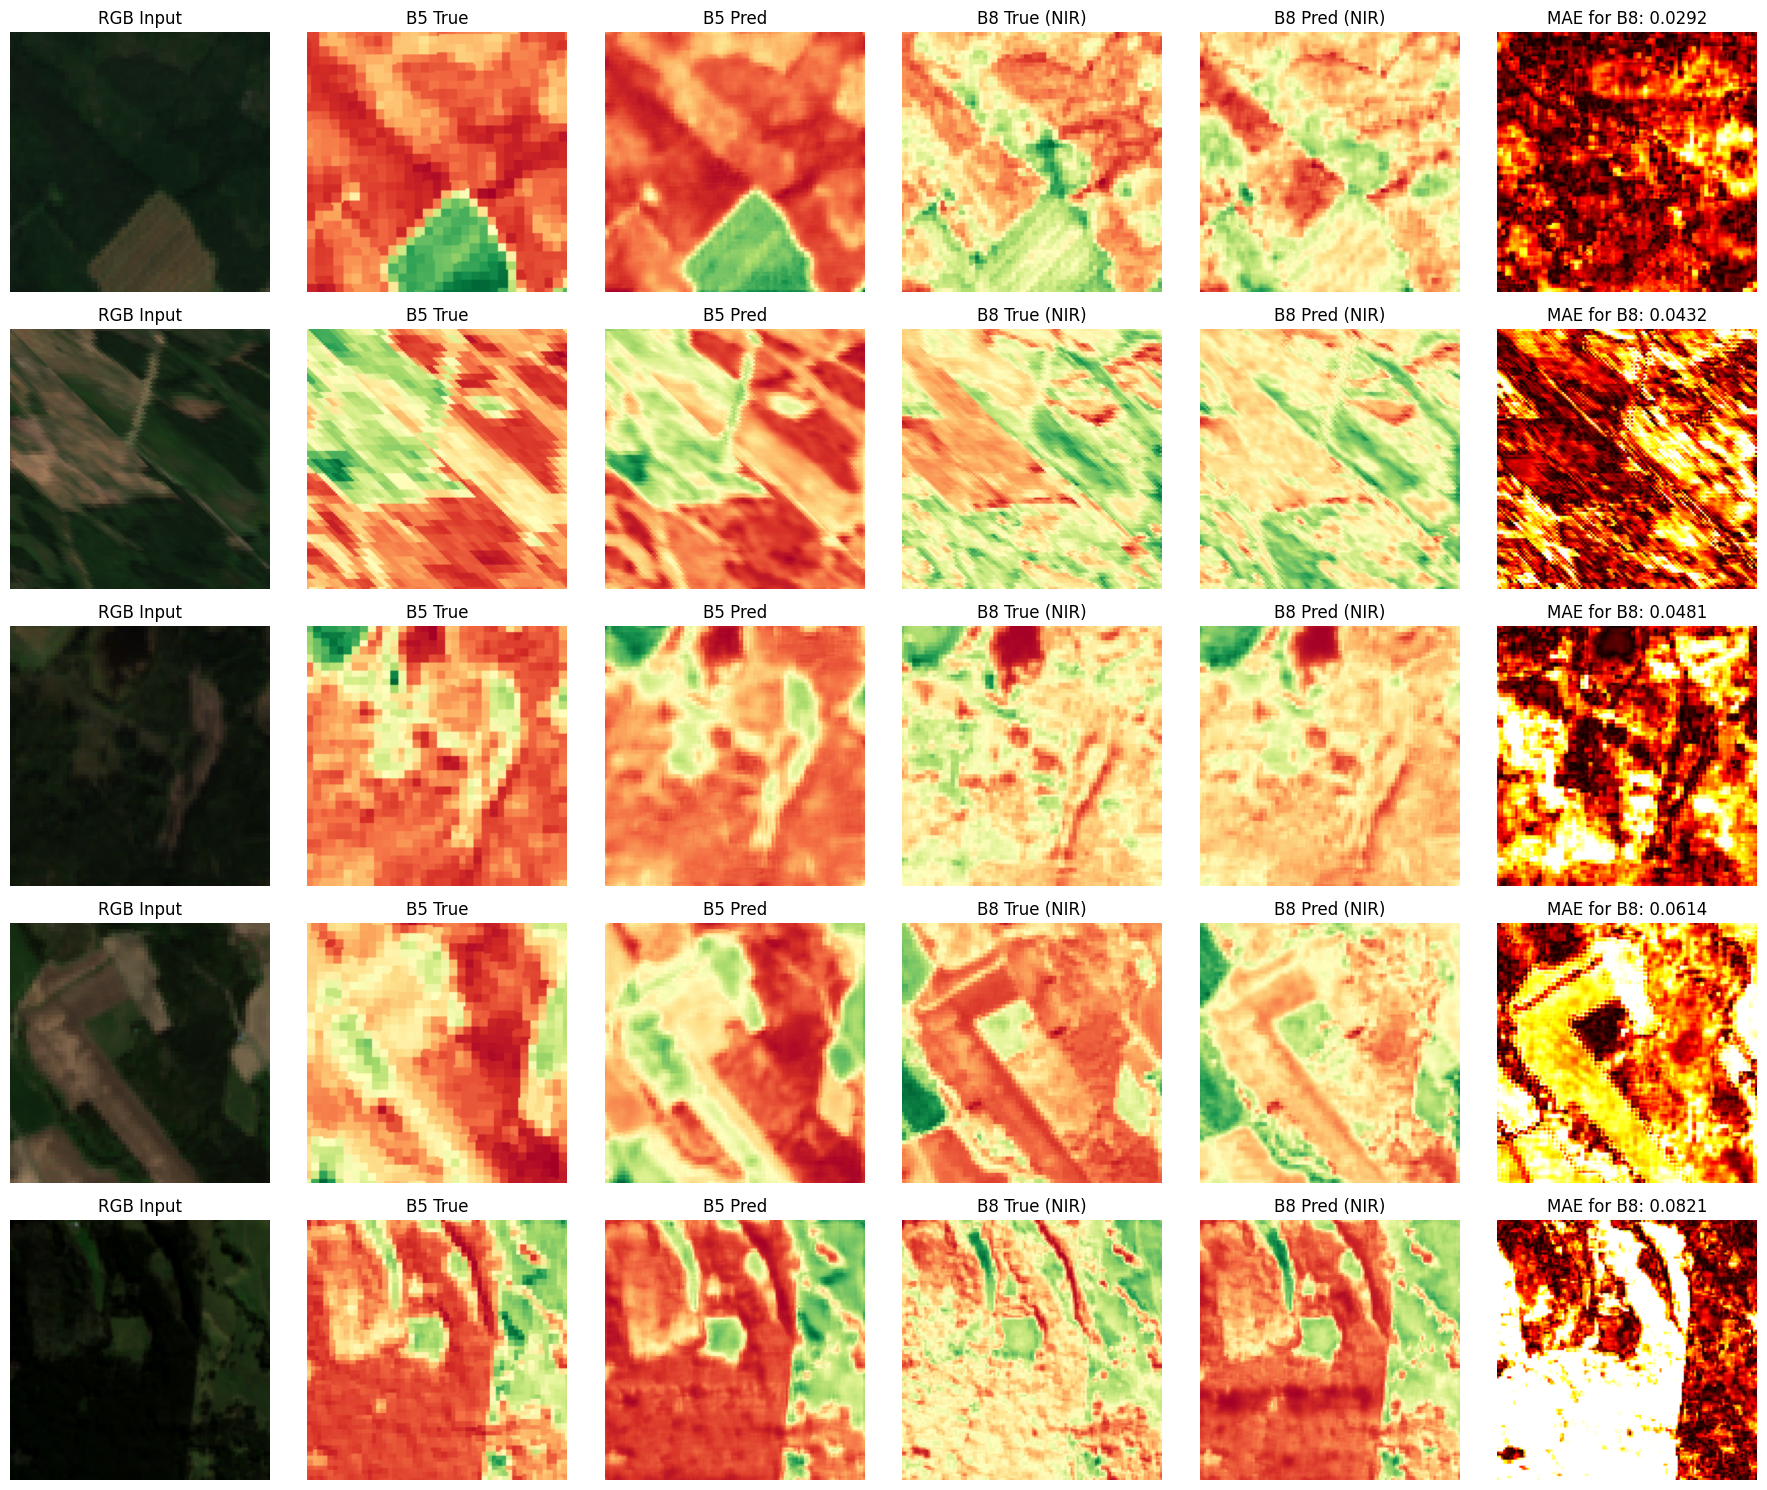

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_predictions(model, dataset, num_samples=3):
    """Visualize some predictions vs ground truth."""

    # Take a batch
    for batch in dataset.take(1):
        if len(batch) == 3:
            rgb_batch, nir_batch, mask_batch = batch
        else:
            rgb_batch, nir_batch = batch
            mask_batch = None

        pred_batch = model(rgb_batch, training=False)

        # Adjust num_samples in case batch is smaller
        actual_samples = min(num_samples, rgb_batch.shape[0])

        fig, axes = plt.subplots(actual_samples, 6, figsize=(18, 3*actual_samples))

        # Handle case where there's only one sample (axes not 2D array)
        if actual_samples == 1:
            axes = axes[np.newaxis, :]

        for i in range(actual_samples):
            rgb = rgb_batch[i].numpy()
            nir_true = nir_batch[i].numpy()
            nir_pred = pred_batch[i].numpy()
            mask = mask_batch[i].numpy() if mask_batch is not None else None

            # RGB
            axes[i, 0].imshow(np.clip(rgb * 3, 0, 1))  # Boost brightness
            axes[i, 0].set_title('RGB Input')
            axes[i, 0].axis('off')

            # B5 (RedEdge 1)
            axes[i, 1].imshow(nir_true[:,:,0], cmap='RdYlGn')
            axes[i, 1].set_title('B5 True')
            axes[i, 1].axis('off')

            axes[i, 2].imshow(nir_pred[:,:,0], cmap='RdYlGn')
            axes[i, 2].set_title('B5 Pred')
            axes[i, 2].axis('off')

            # B8 (NIR)
            axes[i, 3].imshow(nir_true[:,:,3], cmap='RdYlGn')
            axes[i, 3].set_title('B8 True (NIR)')
            axes[i, 3].axis('off')

            axes[i, 4].imshow(nir_pred[:,:,3], cmap='RdYlGn')
            axes[i, 4].set_title('B8 Pred (NIR)')
            axes[i, 4].axis('off')

            # Error (masked if available)
            error = np.abs(nir_true[:,:,3] - nir_pred[:,:,3])
            mae = np.mean(error)
            if mask is not None:
                error = error * mask
                valid_pixels = np.sum(mask)
                if valid_pixels > 0:
                    mae = np.sum(error) / valid_pixels

            im = axes[i, 5].imshow(error, cmap='hot', vmin=0, vmax=0.1)
            axes[i, 5].set_title(f'MAE for B8: {mae:.4f}')
            axes[i, 5].axis('off')

        plt.tight_layout()
        plt.show()

# Select active model (Phase 2 if available, otherwise Phase 1)
active_trainer = trainer_p2 if "trainer_p2" in globals() else trainer
print(f"Using model from: {'Phase 2 (Fine-tuning)' if 'trainer_p2' in globals() else 'Phase 1'}")

# Visualize on test set (if available)
if 'test_ds' in globals() and test_ds is not None:
    print("Visualizing predictions on test set (RANDOM TILES):")
    # Unbatch -> Shuffle -> Batch for truly random tiles
    # Large buffer (2000) for good mixing
    random_test_ds = test_ds.unbatch().shuffle(buffer_size=2000).batch(10)
    visualize_predictions(active_trainer.model, random_test_ds, num_samples=5)
else:
    print("Visualizing predictions on validation set (RANDOM TILES):")
    random_val_ds = val_ds.unbatch().shuffle(buffer_size=2000).batch(10)
    visualize_predictions(active_trainer.model, random_val_ds, num_samples=5)

## 12. Save Complete Model

In [ ]:
# ============================================================================
# SAVE MODEL (normal + EMA)
# ============================================================================

# The EMA model is generally BETTER than the normal model
# It's a moving average of weights that smooths training

"""print("Saving models...")

# Load best normal weights
trainer.model.load_weights('cnn_msgpp_decoder_best.weights.h5')
trainer.model.save('cnn_msgpp_decoder_complete.keras')
print("Normal model saved: cnn_msgpp_decoder_complete.keras")

# Load best EMA weights (if available)
import os
if os.path.exists('cnn_msgpp_decoder_best_ema.weights.h5'):
    trainer.model.load_weights('cnn_msgpp_decoder_best_ema.weights.h5')
    trainer.model.save('cnn_msgpp_decoder_complete_ema.keras')
    print("EMA model saved: cnn_msgpp_decoder_complete_ema.keras")
    print("  Recommended: use the EMA model for inference!")

# Copy to Google Drive
from google.colab import drive
drive.mount('/content/drive')

import shutil
shutil.copy('cnn_msgpp_decoder_complete.keras', '/content/drive/MyDrive/cnn_msgpp_decoder_complete.keras')
shutil.copy('cnn_msgpp_decoder_best.weights.h5', '/content/drive/MyDrive/cnn_msgpp_decoder_best.weights.h5')

if os.path.exists('cnn_msgpp_decoder_best_ema.weights.h5'):
    shutil.copy('cnn_msgpp_decoder_complete_ema.keras', '/content/drive/MyDrive/cnn_msgpp_decoder_complete_ema.keras')
    shutil.copy('cnn_msgpp_decoder_best_ema.weights.h5', '/content/drive/MyDrive/cnn_msgpp_decoder_best_ema.weights.h5')

print("Models copied to Google Drive")"""